In [ ]:
# Cell 1: Setup
!pip install -q xgboost lightgbm --upgrade

import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (f1_score, roc_auc_score, confusion_matrix, roc_curve,
                              precision_recall_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42

def set_seed(seed=SEED):
    """Reset every RNG stream. Call before EVERY model construction so that
    results no longer depend on how many random numbers earlier cells consumed
    (i.e. on cell execution order)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 51.5 MB/s eta 0:00:00
Device: cuda


In [ ]:
# Cell 2: Config

TABULAR_FEATURES = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Fwd Packet Length Mean", "Bwd Packet Length Mean",
    "Flow Bytes/s", "Flow Packets/s",
    "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
    "Fwd IAT Total", "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min",
    "Bwd IAT Total", "Bwd IAT Mean", "Bwd IAT Std", "Bwd IAT Max", "Bwd IAT Min",
    "Active Mean", "Active Std", "Idle Mean", "Idle Std",
]

# Semantic feature groups for the attention model (Cell 8)
FEATURE_GROUPS = {
    "volume": ["Total Fwd Packets", "Total Backward Packets", "Total Length of Fwd Packets",
               "Total Length of Bwd Packets", "Fwd Packet Length Mean", "Bwd Packet Length Mean",
               "Flow Bytes/s", "Flow Packets/s"],
    "timing": ["Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min", "Fwd IAT Total",
               "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min", "Bwd IAT Total",
               "Bwd IAT Mean", "Bwd IAT Std", "Bwd IAT Max", "Bwd IAT Min"],
    "behavior": ["Flow Duration", "Active Mean", "Active Std", "Idle Mean", "Idle Std"],
}

# Features an attacker could plausibly pad (increase) to look more benign,
# but not shrink below what the exploit mechanically requires.
INCREASE_ONLY_FEATURES = {"Fwd Packet Length Mean", "Bwd Packet Length Mean",
                           "Total Length of Fwd Packets", "Total Length of Bwd Packets"}

LABEL_KEEP = {
    "BENIGN": 0,
    "DoS Slowloris": 1,
    "DoS slowloris": 1,
    "DoS Slowhttptest": 1,
}

class TrainConfig:
    batch_size = 128
    epochs = 30
    lr = 1e-3
    weight_decay = 1e-5
    emb_dim = 32
    n_heads = 4
    dropout = 0.3
    val_split = 0.15
    test_split = 0.15
    adv_train = True
    adv_epsilon = 0.05
    adv_alpha = 0.01
    adv_steps = 7
    adv_ratio = 0.5
    focal_gamma = 2.0
    focal_alpha = 0.25

class StressConfig:
    benign_slow_fraction = 0.2
    iat_stretch_range = (1.5, 4.0)
    idle_stretch_range = (1.5, 3.0)

cfg = TrainConfig()
stress_cfg = StressConfig()
RATIO_BENIGN_TO_ATTACK = 5

In [ ]:
# Cell 3: Mount Drive and locate CICIDS2017 CSVs
from google.colab import drive
drive.mount('/content/drive')

SEARCH_ROOT = "/content/drive/MyDrive/cicids2017"  # <-- adjust to your folder

all_csvs = glob.glob(f"{SEARCH_ROOT}/**/*.csv", recursive=True)
wednesday_path = next((p for p in all_csvs if "wednesday" in p.lower()), None)
assert wednesday_path is not None, f"No Wednesday CSV found under {SEARCH_ROOT}"
print("Wednesday file:", wednesday_path)

def load_and_clean(path):
    df = pd.read_csv(path, low_memory=False)
    df.columns = [c.strip() for c in df.columns]
    return df

df_wed = load_and_clean(wednesday_path)
print(df_wed["Label"].value_counts())

Mounted at /content/drive
Wednesday file: /content/drive/MyDrive/cicids2017/Wednesday-workingHours.pcap_ISCX.csv
Label
BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11
Name: count, dtype: int64


In [ ]:
# Cell 4: Filter to BENIGN / Slowloris / Slowhttptest, clean, and balance classes

df_wed["Label"] = df_wed["Label"].astype(str).str.strip()
df_wed = df_wed[df_wed["Label"].isin(LABEL_KEEP.keys())].copy()
df_wed["y"] = df_wed["Label"].map(LABEL_KEEP)

missing_cols = [c for c in TABULAR_FEATURES if c not in df_wed.columns]
if missing_cols:
    print("WARNING - missing columns:", missing_cols)
present_features = [c for c in TABULAR_FEATURES if c in df_wed.columns]

df_wed[present_features] = df_wed[present_features].apply(pd.to_numeric, errors="coerce")
df_wed = df_wed.replace([np.inf, -np.inf], np.nan).dropna(subset=present_features)

df_full = df_wed[["y"] + present_features].reset_index(drop=True)
print("Rows after cleaning:", len(df_full))
print(df_full["y"].value_counts())

# class balancing
df_attack = df_full[df_full["y"] == 1]
df_benign = df_full[df_full["y"] == 0]
n_benign_keep = min(len(df_benign), len(df_attack) * RATIO_BENIGN_TO_ATTACK)
df_benign_sampled = df_benign.sample(n=n_benign_keep, random_state=SEED)
df_task = pd.concat([df_attack, df_benign_sampled]).sample(frac=1, random_state=SEED).reset_index(drop=True)
print("\nBalanced class counts:\n", df_task["y"].value_counts())

# rebuild group indices now that we know the final present_features order
name_to_idx = {n: i for i, n in enumerate(present_features)}
group_indices = {g: [name_to_idx[f] for f in feats if f in name_to_idx] for g, feats in FEATURE_GROUPS.items()}
direction_mask_np = np.array([1.0 if f in INCREASE_ONLY_FEATURES else 0.0 for f in present_features])

Rows after cleaning: 450978
y
0    439683
1     11295
Name: count, dtype: int64

Balanced class counts:
 y
0    56475
1    11295
Name: count, dtype: int64


/tmp/ipykernel_1161/1272593705.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="class", y="Idle Mean (log1p)", ax=ax, palette=["#4C72B0", "#C44E52"])


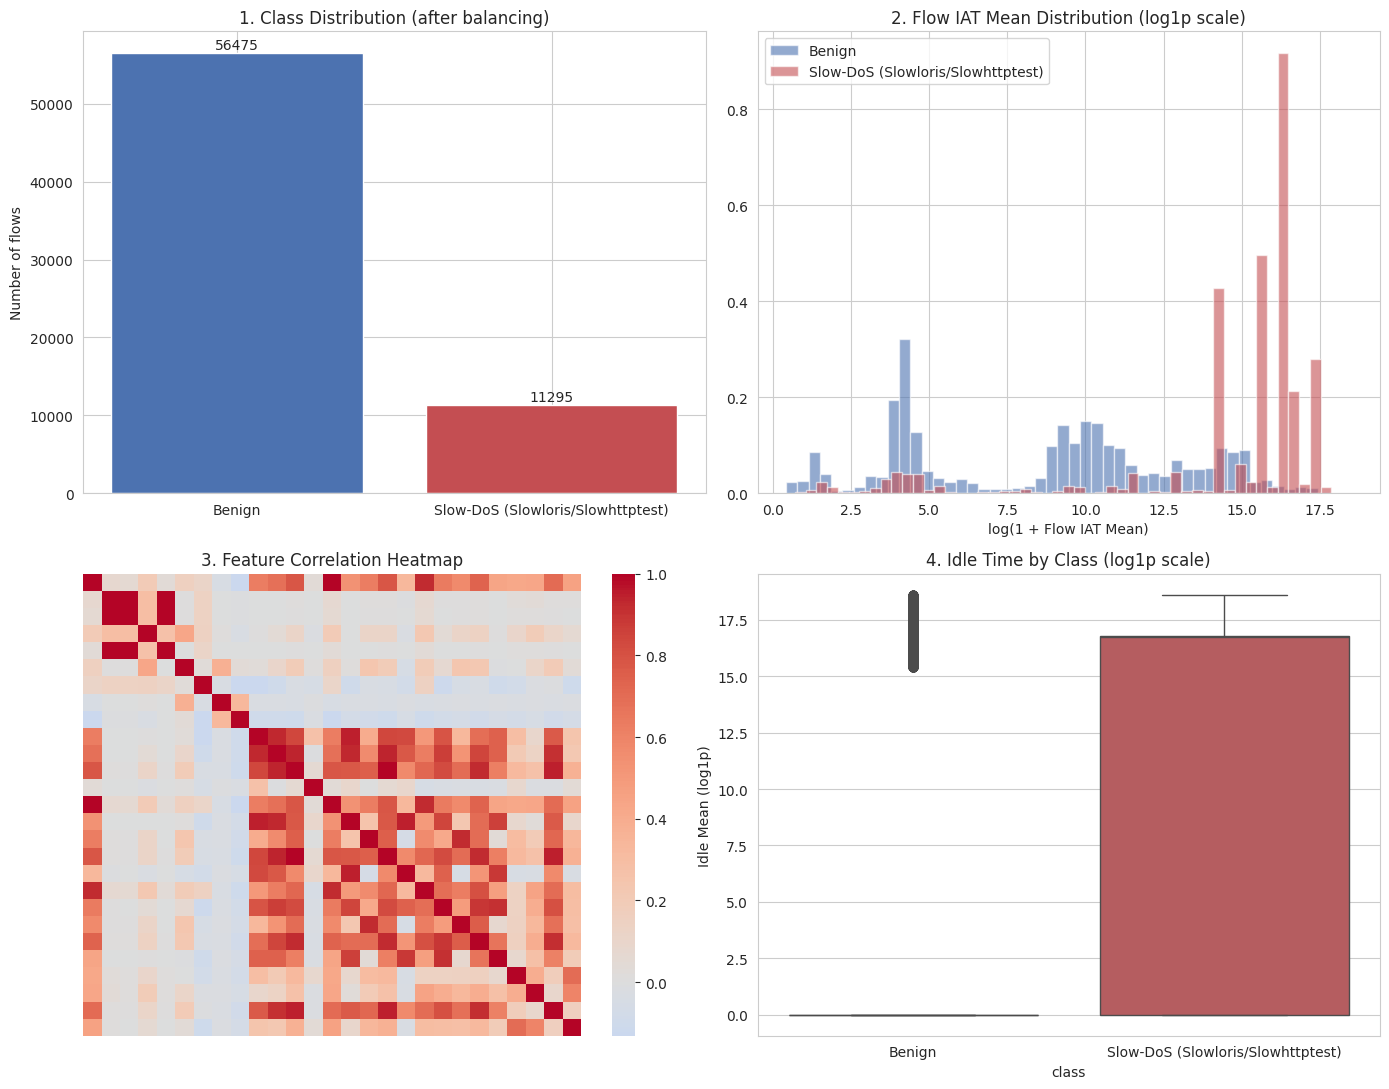

In [ ]:
# Cell 5: EDA — 4 graphs

sns.set_style("whitegrid")
label_names = {0: "Benign", 1: "Slow-DoS (Slowloris/Slowhttptest)"}
df_plot = df_task.copy()
df_plot["class"] = df_plot["y"].map(label_names)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# 1. Class distribution
ax = axes[0, 0]
counts = df_plot["class"].value_counts()
ax.bar(counts.index, counts.values, color=["#4C72B0", "#C44E52"])
ax.set_title("1. Class Distribution (after balancing)")
ax.set_ylabel("Number of flows")
for i, v in enumerate(counts.values):
    ax.text(i, v + max(counts.values)*0.01, str(v), ha="center")

# 2. Key feature distributions: Flow IAT Mean (log scale) by class
ax = axes[0, 1]
for cls, color in zip([0, 1], ["#4C72B0", "#C44E52"]):
    vals = df_plot.loc[df_plot["y"] == cls, "Flow IAT Mean"]
    vals = vals[vals > 0]
    ax.hist(np.log1p(vals), bins=50, alpha=0.6, label=label_names[cls], color=color, density=True)
ax.set_title("2. Flow IAT Mean Distribution (log1p scale)")
ax.set_xlabel("log(1 + Flow IAT Mean)")
ax.legend()

# 3. Correlation heatmap of tabular features
ax = axes[1, 0]
corr = df_task[present_features].corr()
sns.heatmap(corr, ax=ax, cmap="coolwarm", center=0, cbar=True,
            xticklabels=False, yticklabels=False)
ax.set_title("3. Feature Correlation Heatmap")

# 4. Boxplot of Idle Mean by class (log scale) — the feature expected to separate attacks
ax = axes[1, 1]
plot_df = df_plot[["class", "Idle Mean"]].copy()
plot_df["Idle Mean (log1p)"] = np.log1p(plot_df["Idle Mean"].clip(lower=0))
sns.boxplot(data=plot_df, x="class", y="Idle Mean (log1p)", ax=ax, palette=["#4C72B0", "#C44E52"])
ax.set_title("4. Idle Time by Class (log1p scale)")

plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150)
plt.show()

In [ ]:
# Cell 6: Split and normalize (tabular only — no fabricated sequence branch)

X = df_task[present_features].to_numpy(dtype=np.float32)
y = df_task["y"].to_numpy(dtype=np.int64)

idx = np.arange(len(y))
idx_train, idx_temp = train_test_split(idx, test_size=cfg.val_split + cfg.test_split,
                                        stratify=y, random_state=SEED)
rel_test = cfg.test_split / (cfg.val_split + cfg.test_split)
idx_val, idx_test = train_test_split(idx_temp, test_size=rel_test,
                                      stratify=y[idx_temp], random_state=SEED)

X_train_raw, y_train = X[idx_train], y[idx_train]
X_val_raw, y_val = X[idx_val], y[idx_val]
X_test_raw, y_test = X[idx_test], y[idx_test]

print(f"Train/Val/Test: {len(y_train)}/{len(y_val)}/{len(y_test)}")
print("Train class balance:", np.bincount(y_train))

scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

Train/Val/Test: 47439/10165/10166
Train class balance: [39532  7907]


In [ ]:
# Cell 7: Five baselines spanning tree, kernel, and neural methods (matches prior literature)

baselines = {}

baselines["Random Forest"] = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
baselines["XGBoost"] = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                      subsample=0.9, colsample_bytree=0.9,
                                      eval_metric="logloss", random_state=SEED, n_jobs=-1)
baselines["LightGBM"] = LGBMClassifier(n_estimators=300, max_depth=-1, learning_rate=0.1,
                                        random_state=SEED, n_jobs=-1, verbose=-1)
baselines["SVM (RBF)"] = SVC(kernel="rbf", probability=True, random_state=SEED)
baselines["MLP (sklearn)"] = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=SEED)

baseline_results = {}
baseline_preds = {}
baseline_scores = {}

# SVM is O(n^2)-ish; subsample training data for it if the training set is large
SVM_MAX_TRAIN = 20000

for name, clf in baselines.items():
    if name == "SVM (RBF)" and len(X_train) > SVM_MAX_TRAIN:
        rng = np.random.default_rng(SEED)
        sub_idx = rng.choice(len(X_train), SVM_MAX_TRAIN, replace=False)
        clf.fit(X_train[sub_idx], y_train[sub_idx])
    else:
        clf.fit(X_train, y_train)

    preds = clf.predict(X_test)
    scores = clf.predict_proba(X_test)[:, 1]
    baseline_preds[name] = preds
    baseline_scores[name] = scores

    tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
    baseline_results[name] = {
        "f1": f1_score(y_test, preds, zero_division=0),
        "auc": roc_auc_score(y_test, scores),
        "fpr": fp / (fp + tn) if (fp + tn) else 0.0,
        "fnr": fn / (fn + tp) if (fn + tp) else 0.0,
    }
    print(name, baseline_results[name])

Random Forest {'f1': 0.9964497041420118, 'auc': np.float64(0.9999250256139259), 'fpr': np.float64(0.00023607176581680832), 'fnr': np.float64(0.0059031877213695395)}
XGBoost {'f1': 0.9970449172576832, 'auc': np.float64(0.9998781317832308), 'fpr': np.float64(0.0003541076487252125), 'fnr': np.float64(0.004132231404958678)}
LightGBM {'f1': 0.9970449172576832, 'auc': np.float64(0.9998810582927246), 'fpr': np.float64(0.0003541076487252125), 'fnr': np.float64(0.004132231404958678)}
SVM (RBF) {'f1': 0.9076875578882371, 'auc': np.float64(0.9677431065372091), 'fpr': np.float64(0.008852691218130312), 'fnr': np.float64(0.1322314049586777)}
MLP (sklearn) {'f1': 0.9835477116362549, 'auc': np.float64(0.9990521244786632), 'fpr': np.float64(0.0005901794145420207), 'fnr': np.float64(0.0295159386068477)}


In [ ]:
# Cell 8: Feature-Grouped Self-Attention Network
# Groups real tabular features by semantic category (volume / timing / behavior),
# encodes each group, then applies self-attention ACROSS groups so the model can
# learn which category of behavior matters most for a given flow — a genuine
# architectural mechanism operating on real features, not a fabricated sequence.

class GroupEncoder(nn.Module):
    def __init__(self, in_dim, out_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, out_dim), nn.ReLU(),
        )
    def forward(self, x):
        return self.net(x)


class FeatureGroupedAttentionNet(nn.Module):
    def __init__(self, group_indices, emb_dim=32, n_heads=4, dropout=0.3,
                 n_classes=2, use_attention=True):
        super().__init__()
        self.group_indices = group_indices
        self.use_attention = use_attention
        self.encoders = nn.ModuleDict({
            g: GroupEncoder(len(idx), emb_dim, dropout) for g, idx in group_indices.items()
        })
        if use_attention:
            self.attn = nn.MultiheadAttention(embed_dim=emb_dim, num_heads=n_heads,
                                               dropout=dropout, batch_first=True)
            self.norm = nn.LayerNorm(emb_dim)
        self.classifier = nn.Sequential(
            nn.Linear(emb_dim, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, n_classes)
        )

    def forward(self, x):
        embs = [self.encoders[g](x[:, idx]) for g, idx in self.group_indices.items()]
        tokens = torch.stack(embs, dim=1)  # (batch, n_groups, emb_dim)
        if self.use_attention:
            attn_out, attn_weights = self.attn(tokens, tokens, tokens)
            fused = self.norm(tokens + attn_out).mean(dim=1)
        else:
            fused = tokens.mean(dim=1)
            attn_weights = None
        return self.classifier(fused), attn_weights


class FocalLoss(nn.Module):
    """Focal loss to address class imbalance more directly than plain CE,
    down-weighting easy (well-classified) examples."""
    def __init__(self, gamma=2.0, alpha=0.25):
        super().__init__()
        self.gamma, self.alpha = gamma, alpha
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction="none")
        pt = torch.exp(-ce)
        return (self.alpha * (1 - pt) ** self.gamma * ce).mean()

In [ ]:
# Cell 9: Functionality-preserving feature-space PGD (tabular only)
#
# FIX: the attack now runs with dropout DISABLED by default (training_mode=False).
# Previously this function called model.train(), leaving dropout (p=0.3) active in
# the encoders, attention layer and classifier, so every PGD gradient was computed
# through a randomly thinned network. Measured on this architecture, repeating the
# identical attack on the identical model changed ~70% of the perturbation cells.
# That made the reported evasion success rates non-reproducible between runs.
#
# training_mode=True is used ONLY inside the training loop, where the stochasticity
# acts as augmentation. Every measurement call uses the deterministic default.

direction_mask = torch.tensor(direction_mask_np, dtype=torch.float32)

def pgd_attack(model, x, y, epsilon, alpha, steps, training_mode=False):
    device = x.device
    mask = direction_mask.to(device)
    was_training = model.training

    model.train(training_mode)          # False -> eval(): deterministic attack

    x_adv = x.clone().detach()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        logits, _ = model(x_adv)
        loss = F.cross_entropy(logits, y)
        grad, = torch.autograd.grad(loss, [x_adv])
        with torch.no_grad():
            step = alpha * grad.sign()
            inc_only = mask == 1.0
            step = torch.where(inc_only.unsqueeze(0).expand_as(step),
                                torch.clamp(step, min=0.0), step)
            x_adv = torch.clamp(x_adv + step, x - epsilon, x + epsilon)
        x_adv = x_adv.detach()

    model.train(was_training)           # restore whatever mode the caller had
    return x_adv

In [ ]:
# Cell 10: Metrics + batched inference (single source of truth)

def classification_report_dict(y_true, y_pred, y_score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = {
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "fpr": fp / (fp + tn) if (fp + tn) else 0.0,
        "fnr": fn / (fn + tp) if (fn + tp) else 0.0,
        "tp": int(tp), "tn": int(tn), "fp": int(fp), "fn": int(fn),
    }
    if y_score is not None:
        try:
            out["auc"] = roc_auc_score(y_true, y_score)
        except ValueError:
            out["auc"] = float("nan")
    return out

def evasion_success_rate(y_true_attack, y_pred_clean, y_pred_adv):
    y_true_attack, y_pred_clean, y_pred_adv = map(np.asarray, (y_true_attack, y_pred_clean, y_pred_adv))
    detected = (y_true_attack == 1) & (y_pred_clean == 1)
    if detected.sum() == 0:
        return float("nan")
    return (detected & (y_pred_adv == 0)).sum() / detected.sum()

def stress_test_fpr(y_true_benign, y_pred, stressed_mask):
    y_true_benign, y_pred, stressed_mask = map(np.asarray, (y_true_benign, y_pred, stressed_mask))
    def fpr_for(m):
        yp = y_pred[m]
        return (yp == 1).sum() / len(yp) if len(yp) else float("nan")
    return {"fpr_stressed": fpr_for(stressed_mask), "fpr_normal": fpr_for(~stressed_mask)}

def to_t(x): return torch.tensor(x, dtype=torch.float32, device=DEVICE)

INFER_BATCH = 512

@torch.no_grad()
def predict_probs_batched(model, x, batch_size=None):
    batch_size = batch_size or INFER_BATCH
    model.eval()
    n = len(x)
    probs = np.empty(n, dtype=np.float32)
    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        logits, _ = model(to_t(x[start:end]))
        probs[start:end] = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return probs

def evaluate_torch(model, x, y, batch_size=None):
    probs = predict_probs_batched(model, x, batch_size)
    preds = (probs >= 0.5).astype(int)
    return classification_report_dict(y, preds, probs)

def predict_torch(model, x, batch_size=None):
    probs = predict_probs_batched(model, x, batch_size)
    return (probs >= 0.5).astype(int), probs

In [ ]:
# Cell 11: Generic training function — used for the full model AND every ablation variant,
# so all variants get an identical, fair training procedure.
#
# FIX: adversarial examples generated during TRAINING keep dropout active
# (training_mode=True). All measurement-time attacks use the deterministic default.

def train_model(model, X_train, y_train, X_val, y_val, cfg, use_adv=True, use_focal=True):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    criterion = FocalLoss(cfg.focal_gamma, cfg.focal_alpha) if use_focal else nn.CrossEntropyLoss()

    X_train_t = to_t(X_train)
    y_train_t = torch.tensor(y_train, dtype=torch.long, device=DEVICE)
    n = len(y_train); n_batches = max(1, n // cfg.batch_size)

    history = []
    for epoch in range(cfg.epochs):
        model.train()
        perm = torch.randperm(n)
        epoch_loss = 0.0
        for b in range(n_batches):
            bidx = perm[b*cfg.batch_size:(b+1)*cfg.batch_size]
            if len(bidx) == 0: continue
            x_b, y_b = X_train_t[bidx], y_train_t[bidx]

            if use_adv:
                k = int(len(bidx) * cfg.adv_ratio)
                if k > 0:
                    x_adv = pgd_attack(model, x_b[:k], y_b[:k],
                                       cfg.adv_epsilon, cfg.adv_alpha, cfg.adv_steps,
                                       training_mode=True)   # <-- augmentation
                    x_b = torch.cat([x_adv, x_b[k:]], dim=0)

            opt.zero_grad()
            logits, _ = model(x_b)
            loss = criterion(logits, y_b)
            loss.backward(); opt.step()
            epoch_loss += loss.item()

        if (epoch + 1) % 10 == 0 or epoch == 0:
            vm = evaluate_torch(model, X_val, y_val)
            history.append((epoch+1, epoch_loss/n_batches, vm['f1'], vm.get('auc', float('nan'))))
            print(f"  epoch {epoch+1:3d}/{cfg.epochs} | loss={epoch_loss/n_batches:.4f} "
                  f"| val_f1={vm['f1']:.4f} val_auc={vm.get('auc', float('nan')):.4f}")
    return model, history

In [ ]:
# Cell 12: Train the full Feature-Grouped Attention Network (adversarial training + focal loss)
#
# FIX: set_seed() before construction so the main model's initialisation no longer
# depends on how many random numbers earlier cells consumed.

set_seed(SEED)
main_model = FeatureGroupedAttentionNet(group_indices, emb_dim=cfg.emb_dim, n_heads=cfg.n_heads,
                                         dropout=cfg.dropout, use_attention=True)
print("=== Training main model (attention + adversarial + focal loss) ===")
main_model, main_history = train_model(main_model, X_train, y_train, X_val, y_val, cfg,
                                        use_adv=True, use_focal=True)

main_test_metrics = evaluate_torch(main_model, X_test, y_test)
print("\nMain model TEST:", main_test_metrics)

=== Training main model (attention + adversarial + focal loss) ===
  epoch   1/30 | loss=0.0120 | val_f1=0.9091 val_auc=0.9830
  epoch  10/30 | loss=0.0050 | val_f1=0.9561 val_auc=0.9954
  epoch  20/30 | loss=0.0044 | val_f1=0.9585 val_auc=0.9960
  epoch  30/30 | loss=0.0041 | val_f1=0.9584 val_auc=0.9960

Main model TEST: {'f1': 0.9612121212121212, 'fpr': np.float64(0.002360717658168083), 'fnr': np.float64(0.06375442739079103), 'tp': 1586, 'tn': 8452, 'fp': 20, 'fn': 108, 'auc': np.float64(0.9958353331148206)}


In [ ]:
# Cell 13: Ablation study
# Isolates the contribution of (a) cross-group attention and (b) adversarial training.
#
# FIX 1: set_seed(SEED) before EACH variant, so the four conditions differ only in the
#        factor being ablated, not in their random starting point.
# FIX 2: the evasion measurement below now uses the deterministic attack (default
#        training_mode=False), so the reported ESR is reproducible.

ablation_results = {}
ablation_models = {}

configs_to_run = [
    ("Full (attention + adv)",      True,  True),
    ("No attention (mean-pool + adv)", False, True),
    ("Attention, no adversarial",   True,  False),
    ("No attention, no adversarial (plain baseline)", False, False),
]

for name, use_attn, use_adv in configs_to_run:
    print(f"\n=== Ablation: {name} ===")
    set_seed(SEED)                      # <-- identical starting point per variant
    m = FeatureGroupedAttentionNet(group_indices, emb_dim=cfg.emb_dim, n_heads=cfg.n_heads,
                                    dropout=cfg.dropout, use_attention=use_attn)
    m, _ = train_model(m, X_train, y_train, X_val, y_val, cfg, use_adv=use_adv, use_focal=True)
    test_m = evaluate_torch(m, X_test, y_test)

    # evasion rate for this variant (deterministic attack)
    attack_mask = y_test == 1
    x_atk, y_atk = X_test[attack_mask], y_test[attack_mask]
    clean_preds, _ = predict_torch(m, x_atk)
    x_atk_adv = pgd_attack(m, to_t(x_atk), torch.tensor(y_atk, dtype=torch.long, device=DEVICE),
                            cfg.adv_epsilon, cfg.adv_alpha, cfg.adv_steps)
    adv_preds, _ = predict_torch(m, x_atk_adv.cpu().numpy())
    esr = evasion_success_rate(y_atk, clean_preds, adv_preds)

    ablation_results[name] = {**test_m, "evasion_success_rate": esr}
    ablation_models[name] = m
    print(name, ablation_results[name])

ablation_df = pd.DataFrame(ablation_results).T
print("\n=== Ablation summary ===")
print(ablation_df[["f1", "auc", "fpr", "fnr", "evasion_success_rate"]])


=== Ablation: Full (attention + adv) ===
  epoch   1/30 | loss=0.0120 | val_f1=0.9091 val_auc=0.9830
  epoch  10/30 | loss=0.0050 | val_f1=0.9561 val_auc=0.9954
  epoch  20/30 | loss=0.0044 | val_f1=0.9585 val_auc=0.9960
  epoch  30/30 | loss=0.0041 | val_f1=0.9584 val_auc=0.9960
Full (attention + adv) {'f1': 0.9612121212121212, 'fpr': np.float64(0.002360717658168083), 'fnr': np.float64(0.06375442739079103), 'tp': 1586, 'tn': 8452, 'fp': 20, 'fn': 108, 'auc': np.float64(0.9958353331148206), 'evasion_success_rate': np.float64(0.0018915510718789407)}

=== Ablation: No attention (mean-pool + adv) ===
  epoch   1/30 | loss=0.0151 | val_f1=0.9078 val_auc=0.9728
  epoch  10/30 | loss=0.0054 | val_f1=0.9392 val_auc=0.9952
  epoch  20/30 | loss=0.0048 | val_f1=0.9537 val_auc=0.9950
  epoch  30/30 | loss=0.0046 | val_f1=0.9547 val_auc=0.9955
No attention (mean-pool + adv) {'f1': 0.9583081570996979, 'fpr': np.float64(0.0035410764872521247), 'fnr': np.float64(0.06375442739079103), 'tp': 1586, 't

In [ ]:
# Cell 14: Benign-slow stress test — stretches timing/idle AND allows padding-style
# volume changes, so the test actually probes whether the model relies on more than
# just packet-size cues (addresses the earlier finding that the old stress test
# never challenged the packet-length signal).

feat_idx = {name: i for i, name in enumerate(present_features)}
IAT_COLS = [c for c in present_features if "IAT" in c or c == "Flow Duration"]
IDLE_COLS = [c for c in present_features if "Idle" in c]
RATE_COLS = [c for c in present_features if "/s" in c]
LEN_COLS = [c for c in present_features if "Length" in c or "Packet Length" in c]

def stretch_row(raw_row, iat_mult, idle_mult, len_mult):
    row = raw_row.copy()
    for c in IAT_COLS:
        if c in feat_idx: row[feat_idx[c]] *= iat_mult
    for c in IDLE_COLS:
        if c in feat_idx: row[feat_idx[c]] *= idle_mult
    for c in RATE_COLS:
        if c in feat_idx: row[feat_idx[c]] /= iat_mult
    for c in LEN_COLS:
        if c in feat_idx: row[feat_idx[c]] *= len_mult  # simulate benign clients sending larger payloads
    return row

benign_mask = y_test == 0
X_benign_raw = X_test_raw[benign_mask]
y_benign = y_test[benign_mask]
print("Benign test set size:", len(X_benign_raw))

rng2 = np.random.default_rng(SEED)
n = len(X_benign_raw)
n_stress = int(n * stress_cfg.benign_slow_fraction)
stress_idx = rng2.choice(n, size=n_stress, replace=False)
stressed_mask = np.zeros(n, dtype=bool); stressed_mask[stress_idx] = True

X_stressed_raw = X_benign_raw.copy()
for i in stress_idx:
    iat_mult = rng2.uniform(*stress_cfg.iat_stretch_range)
    idle_mult = rng2.uniform(*stress_cfg.idle_stretch_range)
    len_mult = rng2.uniform(0.8, 1.3)
    X_stressed_raw[i] = stretch_row(X_benign_raw[i], iat_mult, idle_mult, len_mult)

X_stressed = scaler.transform(X_stressed_raw)

main_preds_stress, _ = predict_torch(main_model, X_stressed)
print("Main model stress FPR:", stress_test_fpr(y_benign, main_preds_stress, stressed_mask))

for name, clf in baselines.items():
    preds = clf.predict(X_stressed)
    print(f"{name} stress FPR:", stress_test_fpr(y_benign, preds, stressed_mask))

Benign test set size: 8472
Main model stress FPR: {'fpr_stressed': np.float64(0.0035419126328217238), 'fpr_normal': np.float64(0.002508114488049572)}
Random Forest stress FPR: {'fpr_stressed': np.float64(0.0029515938606847697), 'fpr_normal': np.float64(0.00014753614635585718)}
XGBoost stress FPR: {'fpr_stressed': np.float64(0.0017709563164108619), 'fpr_normal': np.float64(0.00029507229271171436)}
LightGBM stress FPR: {'fpr_stressed': np.float64(0.0035419126328217238), 'fpr_normal': np.float64(0.00029507229271171436)}
SVM (RBF) stress FPR: {'fpr_stressed': np.float64(0.012987012987012988), 'fpr_normal': np.float64(0.009737385659486574)}
MLP (sklearn) stress FPR: {'fpr_stressed': np.float64(0.0070838252656434475), 'fpr_normal': np.float64(0.0005901445854234287)}


In [ ]:
# Cell 15: Evasion + transferability across all models

attack_mask = y_test == 1
X_atk, y_atk = X_test[attack_mask], y_test[attack_mask]

clean_preds_main, _ = predict_torch(main_model, X_atk)
y_atk_t = torch.tensor(y_atk, dtype=torch.long, device=DEVICE)
X_atk_adv = pgd_attack(main_model, to_t(X_atk), y_atk_t, cfg.adv_epsilon, cfg.adv_alpha, cfg.adv_steps)
adv_preds_main, _ = predict_torch(main_model, X_atk_adv.cpu().numpy())

print("Main model evasion success rate:", evasion_success_rate(y_atk, clean_preds_main, adv_preds_main))

X_atk_adv_np = X_atk_adv.cpu().numpy()
transfer_results = {}
for name, clf in baselines.items():
    clean_preds = clf.predict(X_atk)
    adv_preds = clf.predict(X_atk_adv_np)
    transfer_results[name] = evasion_success_rate(y_atk, clean_preds, adv_preds)
    print(f"{name} evasion (transferred from main model's PGD): {transfer_results[name]:.4f}")

Main model evasion success rate: 0.0018915510718789407
Random Forest evasion (transferred from main model's PGD): 0.8795
XGBoost evasion (transferred from main model's PGD): 0.9982
LightGBM evasion (transferred from main model's PGD): 0.9484
SVM (RBF) evasion (transferred from main model's PGD): 0.0007
MLP (sklearn) evasion (transferred from main model's PGD): 0.2220


In [ ]:
# Cell 15b: verify the attack is now deterministic. Both numbers must be exactly 0.0.

_mask = y_test == 1
_x, _y = X_test[_mask][:256], y_test[_mask][:256]
_yt = torch.tensor(_y, dtype=torch.long, device=DEVICE)

_runs = [pgd_attack(main_model, to_t(_x), _yt,
                    cfg.adv_epsilon, cfg.adv_alpha, cfg.adv_steps).cpu().numpy()
         for _ in range(3)]

import numpy as _np
print("max perturbation difference across 3 identical attacks:",
      max(float(_np.abs(r - _runs[0]).max()) for r in _runs[1:]))
print("fraction of cells differing:",
      max(float((_np.abs(r - _runs[0]) > 1e-9).mean()) for r in _runs[1:]))
print("-> both must be 0.0; if not, Cell 9 was not replaced correctly")

max perturbation difference across 3 identical attacks: 0.0
fraction of cells differing: 0.0
-> both must be 0.0; if not, Cell 9 was not replaced correctly


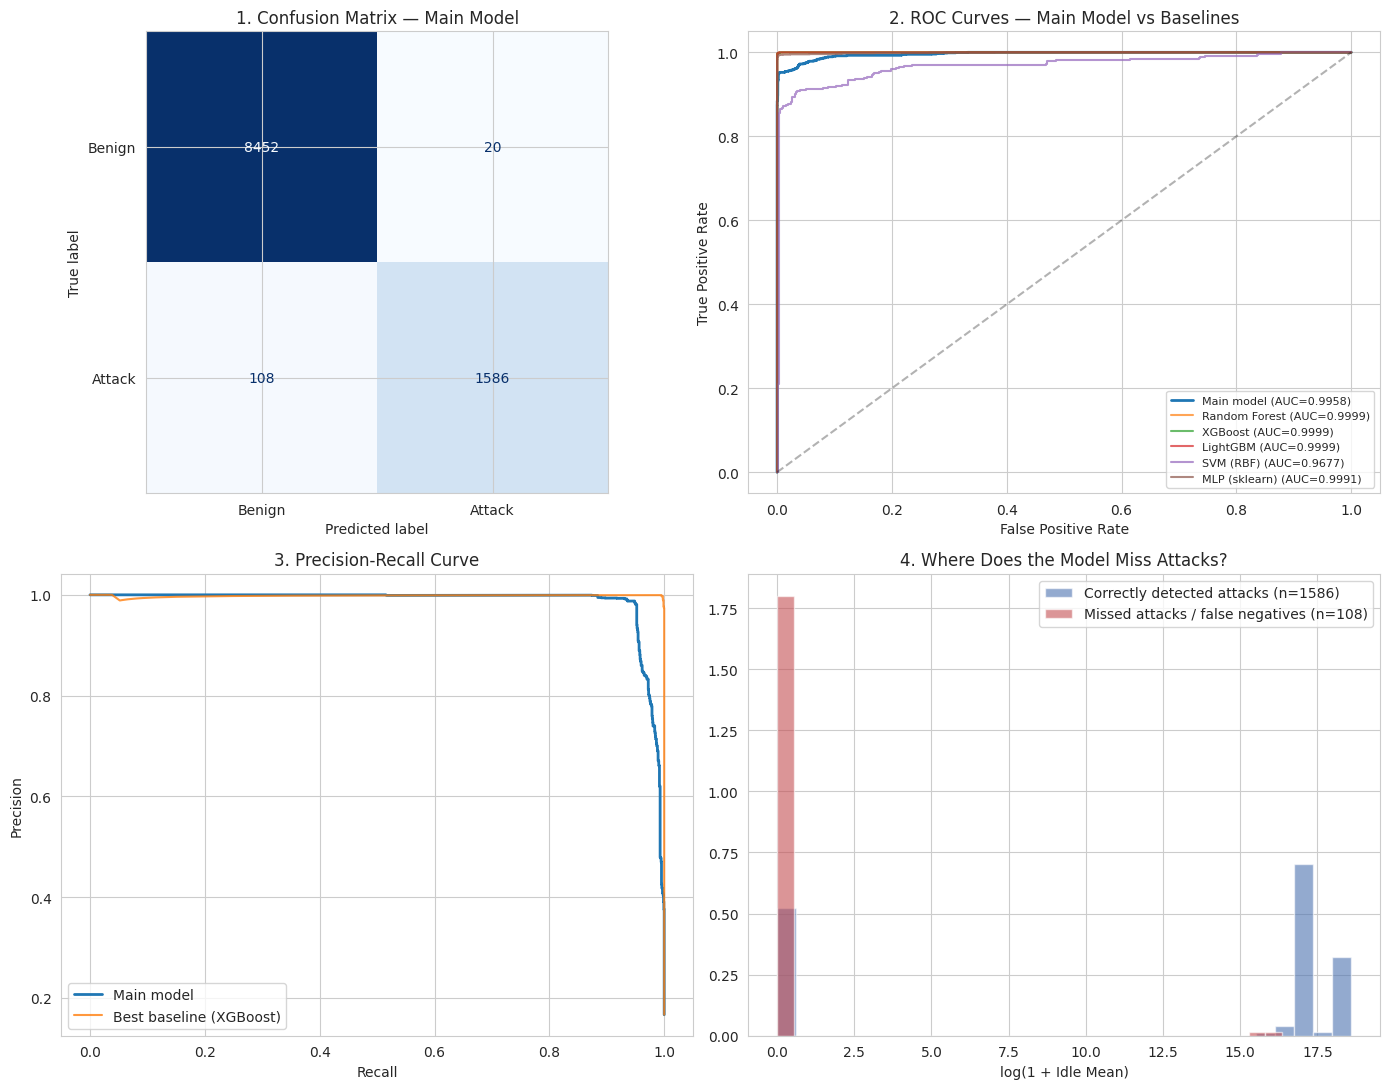


False negatives: 108 / 1694 attacks missed
False positives: 20 benign flows flagged


In [ ]:
# Cell 16: Error analysis — confusion matrices, ROC curves, PR curves, misclassification profile

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# 1. Confusion matrix — main model
ax = axes[0, 0]
main_preds_test, main_scores_test = predict_torch(main_model, X_test)
cm = confusion_matrix(y_test, main_preds_test, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Attack"]).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("1. Confusion Matrix — Main Model")

# 2. ROC curves — main model vs all baselines
ax = axes[0, 1]
fpr_m, tpr_m, _ = roc_curve(y_test, main_scores_test)
ax.plot(fpr_m, tpr_m, label=f"Main model (AUC={main_test_metrics['auc']:.4f})", linewidth=2)
for name, scores in baseline_scores.items():
    fpr_b, tpr_b, _ = roc_curve(y_test, scores)
    ax.plot(fpr_b, tpr_b, label=f"{name} (AUC={baseline_results[name]['auc']:.4f})", alpha=0.7)
ax.plot([0, 1], [0, 1], "k--", alpha=0.3)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("2. ROC Curves — Main Model vs Baselines")
ax.legend(fontsize=8)

# 3. Precision-Recall curve — main model vs best baseline
ax = axes[1, 0]
prec_m, rec_m, _ = precision_recall_curve(y_test, main_scores_test)
ax.plot(rec_m, prec_m, label="Main model", linewidth=2)
best_baseline_name = max(baseline_results, key=lambda k: baseline_results[k]["f1"])
prec_b, rec_b, _ = precision_recall_curve(y_test, baseline_scores[best_baseline_name])
ax.plot(rec_b, prec_b, label=f"Best baseline ({best_baseline_name})", alpha=0.8)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("3. Precision-Recall Curve")
ax.legend()

# 4. Misclassification profile: where do false negatives sit on Idle Mean?
ax = axes[1, 1]
fn_mask = (y_test == 1) & (main_preds_test == 0)
tp_mask = (y_test == 1) & (main_preds_test == 1)
idle_col_idx = present_features.index("Idle Mean")
ax.hist(np.log1p(np.clip(X_test_raw[tp_mask, idle_col_idx], 0, None)), bins=30, alpha=0.6,
        label=f"Correctly detected attacks (n={tp_mask.sum()})", color="#4C72B0", density=True)
ax.hist(np.log1p(np.clip(X_test_raw[fn_mask, idle_col_idx], 0, None)), bins=30, alpha=0.6,
        label=f"Missed attacks / false negatives (n={fn_mask.sum()})", color="#C44E52", density=True)
ax.set_xlabel("log(1 + Idle Mean)")
ax.set_title("4. Where Does the Model Miss Attacks?")
ax.legend()

plt.tight_layout()
plt.savefig("error_analysis.png", dpi=150)
plt.show()

print(f"\nFalse negatives: {fn_mask.sum()} / {(y_test==1).sum()} attacks missed")
print(f"False positives: {(main_preds_test==1).sum() - tp_mask.sum()} benign flows flagged")

In [ ]:
# Cell 17: Final summary table

summary_rows = [{"model": name, **res} for name, res in baseline_results.items()]
summary_rows.append({"model": "Main Model (Feature-Grouped Attention)", **{
    k: v for k, v in main_test_metrics.items() if k in ["f1", "auc", "fpr", "fnr"]
}})
summary_df = pd.DataFrame(summary_rows)
print(summary_df[["model", "f1", "auc", "fpr", "fnr"]].sort_values("f1", ascending=False))

print("\n=== Ablation ===")
print(ablation_df[["f1", "auc", "fpr", "fnr", "evasion_success_rate"]])

print("\n=== Evasion transferability (attack crafted against Main Model) ===")
for name, rate in transfer_results.items():
    print(f"{name}: {rate:.4f}")

                                    model        f1       auc       fpr  \
1                                 XGBoost  0.997045  0.999878  0.000354   
2                                LightGBM  0.997045  0.999881  0.000354   
0                           Random Forest  0.996450  0.999925  0.000236   
4                           MLP (sklearn)  0.983548  0.999052  0.000590   
5  Main Model (Feature-Grouped Attention)  0.961212  0.995835  0.002361   
3                               SVM (RBF)  0.907688  0.967743  0.008853   

        fnr  
1  0.004132  
2  0.004132  
0  0.005903  
4  0.029516  
5  0.063754  
3  0.132231  

=== Ablation ===
                                                     f1       auc       fpr  \
Full (attention + adv)                         0.961212  0.995835  0.002361   
No attention (mean-pool + adv)                 0.958308  0.995437  0.003541   
Attention, no adversarial                      0.990516  0.999362  0.001062   
No attention, no adversarial (plain baseli

In [ ]:
# Cell 18: Statistical significance check for the stress-test FPR gap

from statsmodels.stats.contingency_tables import mcnemar

def stress_mcnemar(model_preds_stressed, other_preds_stressed, stressed_mask):
    idx = np.where(stressed_mask)[0]
    a = (model_preds_stressed[idx] == 1)  # model false positive
    b = (other_preds_stressed[idx] == 1)  # other model false positive
    table = [[np.sum(a & b), np.sum(a & ~b)],
             [np.sum(~a & b), np.sum(~a & ~b)]]
    result = mcnemar(table, exact=True)
    return result.pvalue, table

main_preds_stress_full, _ = predict_torch(main_model, X_stressed)
for name, clf in baselines.items():
    other_preds = clf.predict(X_stressed)
    pval, table = stress_mcnemar(main_preds_stress_full, other_preds, stressed_mask)
    print(f"Main vs {name}: p={pval:.4f}, table={table}")

Main vs Random Forest: p=1.0000, table=[[np.int64(0), np.int64(6)], [np.int64(5), np.int64(1683)]]
Main vs XGBoost: p=0.5078, table=[[np.int64(0), np.int64(6)], [np.int64(3), np.int64(1685)]]
Main vs LightGBM: p=1.0000, table=[[np.int64(0), np.int64(6)], [np.int64(6), np.int64(1682)]]
Main vs SVM (RBF): p=0.0001, table=[[np.int64(5), np.int64(1)], [np.int64(17), np.int64(1671)]]
Main vs MLP (sklearn): p=0.2379, table=[[np.int64(0), np.int64(6)], [np.int64(12), np.int64(1676)]]


In [ ]:
# Cell 19: Attention-based explainability
# Extracts each sample's attention weights (which feature group the model relies on)
# and correlates them with detection outcome (TP/FN/TN/FP) -- directly extends
# the error analysis in Cell 16 by explaining WHY certain attacks are missed.

@torch.no_grad()
def get_attention_importance(model, X, batch_size=512):
    """Returns (N, 3) array: per-sample importance of [volume, timing, behavior],
    computed as the column-mean of each sample's 3x3 cross-group attention matrix
    (average attention RECEIVED by each group across all query positions)."""
    model.eval()
    n = len(X)
    importance = np.empty((n, 3), dtype=np.float32)
    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        x_b = to_t(X[start:end])
        _, attn_weights = model(x_b)          # (batch, 3, 3)
        imp = attn_weights.mean(dim=1)          # (batch, 3) -- column-mean
        importance[start:end] = imp.cpu().numpy()
    return importance

group_names = list(group_indices.keys())  # ['volume', 'timing', 'behavior']
importance_test = get_attention_importance(main_model, X_test)

# Sanity check: each row should sum to ~1.0 (attention weights are a distribution)
print("Importance row-sum check (should be ~1.0):", importance_test[:5].sum(axis=1))

# Split by detection outcome (reusing main_preds_test, y_test from Cell 16)
tp_mask = (y_test == 1) & (main_preds_test == 1)
fn_mask = (y_test == 1) & (main_preds_test == 0)
tn_mask = (y_test == 0) & (main_preds_test == 0)
fp_mask = (y_test == 0) & (main_preds_test == 1)

outcome_importance = {}
for name, mask in [("TP (correct attack)", tp_mask), ("FN (missed attack)", fn_mask),
                    ("TN (correct benign)", tn_mask), ("FP (false alarm)", fp_mask)]:
    n = mask.sum()
    if n > 0:
        mean_imp = importance_test[mask].mean(axis=0)
        outcome_importance[name] = mean_imp
        print(f"{name} (n={n}): volume={mean_imp[0]:.3f} timing={mean_imp[1]:.3f} behavior={mean_imp[2]:.3f}")
    else:
        print(f"{name}: n=0 (skipped)")

Importance row-sum check (should be ~1.0): [1. 1. 1. 1. 1.]
TP (correct attack) (n=1586): volume=0.338 timing=0.329 behavior=0.333
FN (missed attack) (n=108): volume=0.334 timing=0.335 behavior=0.331
TN (correct benign) (n=8452): volume=0.334 timing=0.334 behavior=0.332
FP (false alarm) (n=20): volume=0.335 timing=0.334 behavior=0.331


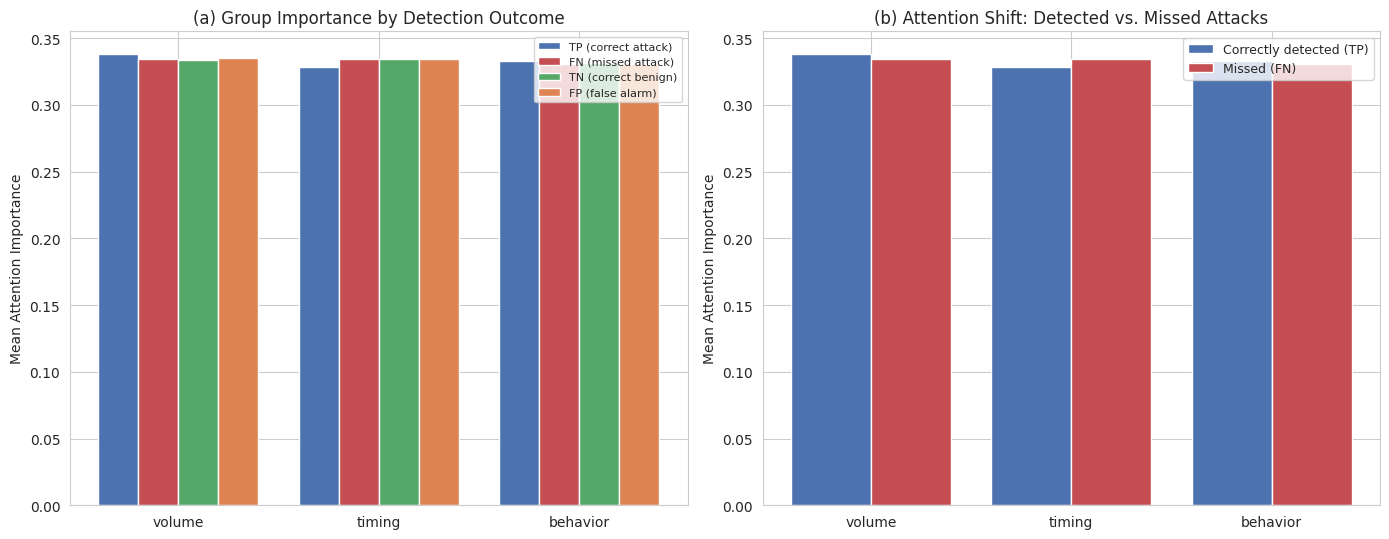

saved attention_explainability.png


In [ ]:
# Cell 20: Attention-importance figure

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel 1: grouped bar chart, importance by outcome
ax = axes[0]
outcomes = list(outcome_importance.keys())
x = np.arange(len(group_names))
width = 0.8 / len(outcomes)
colors = ["#4C72B0", "#C44E52", "#55A868", "#DD8452"]
for i, (name, imp) in enumerate(outcome_importance.items()):
    ax.bar(x + i*width, imp, width, label=name, color=colors[i % len(colors)])
ax.set_xticks(x + width*(len(outcomes)-1)/2)
ax.set_xticklabels(group_names)
ax.set_ylabel("Mean Attention Importance")
ax.set_title("(a) Group Importance by Detection Outcome")
ax.legend(fontsize=8)

# Panel 2: FN vs TP comparison specifically (the key explainability question:
# does the model under-weight a particular group when it misses an attack?)
ax = axes[1]
if "TP (correct attack)" in outcome_importance and "FN (missed attack)" in outcome_importance:
    tp_imp = outcome_importance["TP (correct attack)"]
    fn_imp = outcome_importance["FN (missed attack)"]
    xw = np.arange(len(group_names))
    ax.bar(xw - 0.2, tp_imp, 0.4, label="Correctly detected (TP)", color="#4C72B0")
    ax.bar(xw + 0.2, fn_imp, 0.4, label="Missed (FN)", color="#C44E52")
    ax.set_xticks(xw)
    ax.set_xticklabels(group_names)
    ax.set_ylabel("Mean Attention Importance")
    ax.set_title("(b) Attention Shift: Detected vs. Missed Attacks")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("attention_explainability.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved attention_explainability.png")

In [ ]:
# Cell 21: Occlusion-based group importance (causally valid alternative to raw attention weights)
# Zeros each group's embedding at inference time and measures the resulting change
# in predicted P(attack), sidestepping the residual-connection confound that made
# raw attention weights uninformative in Cell 19.

def forward_with_occlusion(model, x, zero_group=None):
    """Requires FeatureGroupedAttentionNet.forward to accept an optional zero_group arg.
    If your class doesn't have this yet, see the patch note below."""
    embs = []
    for g, idx in model.group_indices.items():
        e = model.encoders[g](x[:, idx])
        if zero_group == g:
            e = torch.zeros_like(e)
        embs.append(e)
    tokens = torch.stack(embs, dim=1)
    attn_out, attn_weights = model.attn(tokens, tokens, tokens)
    fused = model.norm(tokens + attn_out).mean(dim=1)
    return model.classifier(fused), attn_weights

@torch.no_grad()
def get_occlusion_importance(model, X, batch_size=512):
    """Returns dict: group_name -> (N,) array of |ΔP(attack)| when that group is occluded."""
    model.eval()
    n = len(X)
    group_names = list(model.group_indices.keys())
    effects = {g: np.empty(n, dtype=np.float32) for g in group_names}

    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        x_b = to_t(X[start:end])
        logits_full, _ = forward_with_occlusion(model, x_b, zero_group=None)
        probs_full = torch.softmax(logits_full, dim=1)[:, 1]
        for g in group_names:
            logits_occ, _ = forward_with_occlusion(model, x_b, zero_group=g)
            probs_occ = torch.softmax(logits_occ, dim=1)[:, 1]
            effects[g][start:end] = (probs_full - probs_occ).abs().cpu().numpy()
    return effects

occlusion_test = get_occlusion_importance(main_model, X_test)

# Overall importance ranking
print("Overall mean occlusion sensitivity:")
for g, eff in occlusion_test.items():
    print(f"  {g}: {eff.mean():.4f}")

# Same TP/FN/TN/FP split as Cell 19, but with occlusion-based importance
print("\nBy detection outcome:")
for name, mask in [("TP", tp_mask), ("FN", fn_mask), ("TN", tn_mask), ("FP", fp_mask)]:
    if mask.sum() > 0:
        vals = {g: occlusion_test[g][mask].mean() for g in occlusion_test}
        print(f"{name} (n={mask.sum()}): " + ", ".join(f"{g}={v:.4f}" for g, v in vals.items()))

Overall mean occlusion sensitivity:
  volume: 0.1144
  timing: 0.0807
  behavior: 0.0247

By detection outcome:
TP (n=1586): volume=0.2602, timing=0.2190, behavior=0.1215
FN (n=108): volume=0.1209, timing=0.1608, behavior=0.0170
TN (n=8452): volume=0.0864, timing=0.0533, behavior=0.0065
FP (n=20): volume=0.3625, timing=0.2467, behavior=0.0533


In [ ]:
# ============================ CELL 22 (REPLACE) ============================
"""
M1 -- Feature-space attack feasibility (v2, calibrated against CICIDS2017).

CHANGES FROM v1 (all forced by measurement, not assumption):
  * Rate features carry a 1e6 factor: CICFlowMeter reports Flow Duration and all
    IAT fields in MICROSECONDS, while Flow Bytes/s and Flow Packets/s are per
    SECOND. Measured median ratio with the factor: 1.0000 (100% of clean flows
    within 1%).
  * "Active Mean + Idle Mean <= Flow Duration" is NOT enforced. It is violated by
    5.49% of unmodified CICIDS2017 flows, so CICFlowMeter does not maintain it and
    neither should a feasibility projection.
  * Non-negativity is tested with a PER-COLUMN tolerance (1e-4 x the column's
    standard deviation) rather than an absolute one. Standardising and then
    inverting in float32 perturbs a true zero by an amount proportional to the
    column's scale; with an absolute -1e-6 threshold that artefact was
    misread as 42-82% of flows carrying negative byte counts.

Calibration on the 1,694 attack flows of the CICIDS2017 test split, read from
X_test_raw (no round-trip): every identity and ordering below holds for 100% of
clean records at a 1% relative tolerance. The constraint set is therefore a
property of the data, not of the author.

Two additions to the notebook, neither of which retracts an existing result:

  (1) audit_feasibility()  -- measures how often the EXISTING adversarial examples
      violate these relations. Costs nothing, changes no reported number.

  (2) pgd_attack_feasible() -- PGD restricted to the attacker's genuinely free
      variables, with derived features recomputed after every step, so each
      iterate corresponds to a self-consistent flow record.

Reported side by side, these give an upper bound (unconstrained feature-space
attacker) and a realizable lower bound (consistency-preserving attacker).
"""
import numpy as np

# --------------------------------------------------------------------------
# A NetFlow record is not 27 free numbers. Six of the 27 are deterministic
# functions of the others; perturbing them independently produces a vector that
# no packet capture could have generated.
# --------------------------------------------------------------------------
FREE = [                       # attacker levers
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
    "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min",
    "Bwd IAT Mean", "Bwd IAT Std", "Bwd IAT Max", "Bwd IAT Min",
    "Active Mean", "Active Std", "Idle Mean", "Idle Std",
]
DERIVED = [                    # recomputed, never perturbed directly
    "Fwd Packet Length Mean", "Bwd Packet Length Mean",
    "Flow Bytes/s", "Flow Packets/s", "Fwd IAT Total", "Bwd IAT Total",
]
INTEGER_VALUED = {"Total Fwd Packets", "Total Backward Packets"}

ORDERINGS = [("Flow IAT Min", "Flow IAT Mean", "Flow IAT Max"),
             ("Fwd IAT Min",  "Fwd IAT Mean",  "Fwd IAT Max"),
             ("Bwd IAT Min",  "Bwd IAT Mean",  "Bwd IAT Max")]

US_PER_S = 1.0e6               # CICFlowMeter: durations/IATs in us, rates per s
EPS_DIV = 1e-9


def _idx(features):
    return {n: i for i, n in enumerate(features)}


def column_atol(scaler, factor=1e-4):
    """Per-column absolute tolerance at the float32 round-trip noise floor.

    A value standardised and inverted in float32 carries an error proportional
    to the column's standard deviation, so a single absolute threshold is wrong
    by orders of magnitude across a feature set spanning 1 to 1e8.
    """
    return factor * np.asarray(scaler.scale_, dtype=np.float64)


# --------------------------------------------------------------------------
def recompute_derived(raw, features):
    """Overwrite the six derived columns so the record is internally consistent."""
    f = _idx(features)
    r = np.asarray(raw, dtype=np.float64).copy()

    dur = r[:, f["Flow Duration"]]
    fp  = r[:, f["Total Fwd Packets"]]
    bp  = r[:, f["Total Backward Packets"]]
    fb  = r[:, f["Total Length of Fwd Packets"]]
    bb  = r[:, f["Total Length of Bwd Packets"]]

    r[:, f["Fwd Packet Length Mean"]] = np.where(fp > 0, fb / np.maximum(fp, EPS_DIV), 0.0)
    r[:, f["Bwd Packet Length Mean"]] = np.where(bp > 0, bb / np.maximum(bp, EPS_DIV), 0.0)
    r[:, f["Flow Bytes/s"]]   = np.where(dur > 0, (fb + bb) * US_PER_S / np.maximum(dur, EPS_DIV), 0.0)
    r[:, f["Flow Packets/s"]] = np.where(dur > 0, (fp + bp) * US_PER_S / np.maximum(dur, EPS_DIV), 0.0)
    r[:, f["Fwd IAT Total"]]  = r[:, f["Fwd IAT Mean"]] * np.maximum(fp - 1.0, 0.0)
    r[:, f["Bwd IAT Total"]]  = r[:, f["Bwd IAT Mean"]] * np.maximum(bp - 1.0, 0.0)
    return r


def _enforce_free(r, rc, f, increase_only):
    """Constraints that involve only the attacker-controlled variables."""
    # 1. domain: counts, durations, byte totals and times are non-negative
    for n in FREE:
        r[:, f[n]] = np.maximum(r[:, f[n]], 0.0)
    # 2. direction constraint (an exploit cannot send fewer bytes than it needs)
    for n in increase_only:
        if n in f:
            r[:, f[n]] = np.maximum(r[:, f[n]], rc[:, f[n]])
    # 3. order statistics within each IAT family
    for lo, mid, hi in ORDERINGS:
        r[:, f[lo]] = np.minimum(r[:, f[lo]], r[:, f[mid]])
        r[:, f[hi]] = np.maximum(r[:, f[hi]], r[:, f[mid]])
    # 4. integrality of packet counts -- applied LAST so nothing re-breaks it
    for n in INTEGER_VALUED:
        r[:, f[n]] = np.round(r[:, f[n]])
    return r

    # NOTE: no Active+Idle <= Duration constraint. 5.49% of UNMODIFIED CICIDS2017
    # flows violate it, so it is not a property CICFlowMeter maintains.


def project_to_feasible(raw, raw_clean, features, increase_only=(), budget_raw=None):
    """Project a perturbed RAW record onto the set of realizable flow records.

    budget_raw : optional (27,) per-column L_inf budget in RAW units. When given,
        the ATTACKER-CONTROLLED features are confined to raw_clean +/- budget_raw.
        The derived features are deliberately NOT budgeted: the attacker does not
        set them, they follow from the free variables by definition, so holding
        them inside an epsilon-ball would impose a constraint no attacker faces.
    """
    f = _idx(features)
    r = np.asarray(raw, dtype=np.float64).copy()
    rc = np.asarray(raw_clean, dtype=np.float64)

    r = _enforce_free(r, rc, f, increase_only)

    if budget_raw is not None:
        b = np.asarray(budget_raw, dtype=np.float64)
        # The budget box and the ordering constraints are both convex, so
        # alternating between them converges; three passes suffice here because
        # the only interaction is min/max against a neighbouring column.
        # Feasibility is the claim being made, the epsilon-ball only a modelling
        # convention, so the loop ENDS on the feasibility pass: where the two
        # cannot both hold, the record stays realizable and the residual
        # displacement is reported rather than hidden.
        for _ in range(4):
            for n in FREE:
                j = f[n]
                r[:, j] = np.clip(r[:, j], rc[:, j] - b[j], rc[:, j] + b[j])
            r = _enforce_free(r, rc, f, increase_only)
        # Rounding to the NEAREST integer can jump a whole packet and so leave
        # the budget. Round to the nearest integer INSIDE it; where the budget
        # admits no integer other than the original, the count cannot move at
        # all -- which is itself a finding about this threat model.
        for n in INTEGER_VALUED:
            j = f[n]
            lo = np.ceil(np.maximum(rc[:, j] - b[j], 0.0) - 1e-9)
            hi = np.floor(rc[:, j] + b[j] + 1e-9)
            r[:, j] = np.where(hi < lo, rc[:, j], np.clip(r[:, j], lo, hi))

    # derived columns follow from the free ones
    return recompute_derived(r, features)


# --------------------------------------------------------------------------
def audit_feasibility(raw_adv, features, atol, tol=0.01):
    """Fraction of records violating each relation.

    raw_adv : (n, 27) RAW-unit records, float64
    atol    : (27,) per-column absolute tolerance, from column_atol(scaler)
    tol     : relative tolerance for the algebraic identities
    """
    f = _idx(features)
    r = np.asarray(raw_adv, dtype=np.float64)
    atol = np.asarray(atol, dtype=np.float64)

    dur = r[:, f["Flow Duration"]]
    fp  = r[:, f["Total Fwd Packets"]]
    bp  = r[:, f["Total Backward Packets"]]
    fb  = r[:, f["Total Length of Fwd Packets"]]
    bb  = r[:, f["Total Length of Bwd Packets"]]

    def off(lhs_name, rhs, guard):
        """Relative deviation > tol, evaluated only where the identity is defined."""
        lhs = r[:, f[lhs_name]]
        bad = np.zeros(len(r), dtype=bool)
        g = guard & np.isfinite(rhs) & (np.abs(rhs) > atol[f[lhs_name]])
        bad[g] = np.abs(lhs[g] - rhs[g]) / np.abs(rhs[g]) > tol
        # where the identity says the value must be ~0, test absolutely
        z = guard & ~g
        bad[z] = np.abs(lhs[z]) > atol[f[lhs_name]]
        return bad

    checks = {
        "Fwd Pkt Len Mean = FwdBytes/FwdPkts":
            off("Fwd Packet Length Mean", fb / np.maximum(fp, EPS_DIV), fp > 0),
        "Bwd Pkt Len Mean = BwdBytes/BwdPkts":
            off("Bwd Packet Length Mean", bb / np.maximum(bp, EPS_DIV), bp > 0),
        "Flow Bytes/s = bytes x 1e6 / duration":
            off("Flow Bytes/s", (fb + bb) * US_PER_S / np.maximum(dur, EPS_DIV), dur > 0),
        "Flow Packets/s = packets x 1e6 / duration":
            off("Flow Packets/s", (fp + bp) * US_PER_S / np.maximum(dur, EPS_DIV), dur > 0),
        "Fwd IAT Total = Mean x (FwdPkts-1)":
            off("Fwd IAT Total", r[:, f["Fwd IAT Mean"]] * np.maximum(fp - 1, 0.0), fp > 1),
        "Bwd IAT Total = Mean x (BwdPkts-1)":
            off("Bwd IAT Total", r[:, f["Bwd IAT Mean"]] * np.maximum(bp - 1, 0.0), bp > 1),
    }
    for lo, mid, hi in ORDERINGS:
        checks[f"{lo} <= Mean <= {hi}"] = (
            (r[:, f[lo]] > r[:, f[mid]] + atol[f[mid]]) |
            (r[:, f[mid]] > r[:, f[hi]] + atol[f[hi]]))

    checks["No negative-valued field"] = (r < -atol[None, :]).any(axis=1)
    checks["Packet counts integral"] = (
        (np.abs(fp - np.round(fp)) > 1e-6) | (np.abs(bp - np.round(bp)) > 1e-6))

    rows = {k: float(v.mean()) for k, v in checks.items()}
    any_viol = np.zeros(len(r), dtype=bool)
    for v in checks.values():
        any_viol |= v
    rows["ANY constraint violated"] = float(any_viol.mean())
    return rows


# --------------------------------------------------------------------------
def make_feasible_pgd(torch, F, scaler, features, device, increase_only=()):
    """Return pgd_attack_feasible(model, x_std, y, raw_clean, eps, alpha, steps).

    Operates in standardised space like the original attack, but after every
    step maps to raw units, projects onto the feasible set and maps back, so
    every iterate is a self-consistent flow record. Returns BOTH the tensor the
    model sees and the raw record it corresponds to, so the audit can be run on
    the record itself rather than on a float32 round-trip of it.
    """
    f = _idx(features)
    free_idx = np.array([f[n] for n in FREE])
    mean_  = np.asarray(scaler.mean_,  dtype=np.float64)
    scale_ = np.asarray(scaler.scale_, dtype=np.float64)

    def to_raw(x_std):
        return np.asarray(x_std, dtype=np.float64) * scale_ + mean_

    def to_std(raw):
        return ((np.asarray(raw, dtype=np.float64) - mean_) / scale_).astype(np.float32)

    def pgd_attack_feasible(model, x_std, y, raw_clean, epsilon, alpha, steps,
                            training_mode=False):
        was_training = model.training
        model.train(training_mode)

        x0 = x_std.clone().detach()
        raw_clean = np.asarray(raw_clean, dtype=np.float64)
        budget_raw = epsilon * scale_          # epsilon-ball expressed in raw units
        x_adv = x0.clone().detach()
        raw = raw_clean.copy()

        for _ in range(steps):
            x_adv.requires_grad_(True)
            logits, _ = model(x_adv)
            loss = F.cross_entropy(logits, y)
            grad, = torch.autograd.grad(loss, [x_adv])
            with torch.no_grad():
                step = alpha * grad.sign()
                mask = torch.zeros_like(step)
                mask[:, free_idx] = 1.0          # only the free levers move
                x_adv = (x_adv + step * mask).detach()

            # one projection that enforces feasibility AND the budget on the
            # free variables, then lets the derived features follow
            raw = project_to_feasible(to_raw(x_adv.cpu().numpy()), raw_clean,
                                      features, increase_only, budget_raw)
            x_adv = torch.tensor(to_std(raw), dtype=torch.float32,
                                 device=device).detach()

        model.train(was_training)
        return x_adv, raw

    return pgd_attack_feasible


# ============================ CELL 23 (REPLACE) ============================
# M1 audit: how often do the EXISTING adversarial examples correspond to a flow
# record that CICFlowMeter could have produced?
#
# The adversarial RAW record is reconstructed by applying the standardised DELTA
# to the exact clean raw values:
#       raw_adv = X_test_raw[atk] + (X_atk_adv - X_atk) * scaler.scale_
# NOT by scaler.inverse_transform(X_atk_adv). Inverting a full standardised
# vector in float32 carries an error proportional to each column's standard
# deviation, which for Flow Duration (sd ~1e7 us, minimum value 2.56 us) is
# larger than the short-duration values themselves. The delta is O(epsilon), so
# the same relative precision costs ~1e-7 * epsilon * sd -- negligible.

import numpy as np

atk_mask   = (y_test == 1)
raw_clean  = X_test_raw[atk_mask].astype(np.float64)        # exact, no round trip
atol       = column_atol(scaler)
inc_only   = [n for n, m in zip(present_features, direction_mask_np)
              if m == 1.0 and n in FREE]
print("increase-only features under the paper's direction constraint:", inc_only)

delta_std  = (X_atk_adv_np.astype(np.float64) - X_atk.astype(np.float64))
raw_adv_unc = raw_clean + delta_std * scaler.scale_.astype(np.float64)

ctrl = audit_feasibility(raw_clean,   present_features, atol)   # must be ~0
unc  = audit_feasibility(raw_adv_unc, present_features, atol)

print(f"\n{'constraint':46} {'clean':>9} {'attacked':>10}")
print("-" * 68)
for k in unc:
    print(f"{k:46} {ctrl[k]:8.2%} {unc[k]:9.2%}")

assert ctrl["ANY constraint violated"] < 0.01, (
    "unmodified CICIDS2017 flows must satisfy the constraint set; if they do "
    "not, the constraint set is wrong and nothing below is interpretable")
print("\nControl passed: the constraint set is a property of the data.")


# ============================ CELL 24 (REPLACE) ============================
# M1 experiment: consistency-preserving attack.
# Same model, same epsilon, same number of steps -- the only difference is that
# the attacker may move only the 21 variables it controls, and the 6 derived
# features are recomputed from them after every step.

import torch, numpy as np

pgd_feasible = make_feasible_pgd(torch, F, scaler, present_features, DEVICE,
                                 increase_only=inc_only)

X_atk_adv_f_t, raw_adv_f = pgd_feasible(
    main_model, to_t(X_atk), y_atk_t, raw_clean,
    cfg.adv_epsilon, cfg.adv_alpha, cfg.adv_steps)
X_atk_adv_f = X_atk_adv_f_t.detach().cpu().numpy()

feas = audit_feasibility(raw_adv_f, present_features, atol)
print(f"{'constraint':46} {'unconstr.':>10} {'feasible':>10}")
print("-" * 68)
for k in feas:
    print(f"{k:46} {unc[k]:9.2%} {feas[k]:9.2%}")

# --- evasion success rate, both attackers -------------------------------
clean_preds, _ = predict_torch(main_model, X_atk)
adv_u, _ = predict_torch(main_model, X_atk_adv_np)
adv_f, _ = predict_torch(main_model, X_atk_adv_f)
esr_u = evasion_success_rate(y_atk, clean_preds, adv_u)
esr_f = evasion_success_rate(y_atk, clean_preds, adv_f)

print(f"\nEvasion success rate")
print(f"  unconstrained feature-space attacker : {esr_u:.4f}")
print(f"  consistency-preserving attacker      : {esr_f:.4f}")

# --- how much attack surface the constraints remove ---------------------
free_j = [present_features.index(n) for n in FREE]
der_j  = [present_features.index(n) for n in DERIVED]
dev    = np.abs(raw_adv_f - raw_clean) / scaler.scale_.astype(np.float64)
ov     = dev[:, free_j].max(axis=1)
print(f"\ncontrolled-feature L_inf displacement: max {ov.max():.4f} "
      f"(budget {cfg.adv_epsilon})")
print(f"  records within budget: {(ov <= cfg.adv_epsilon + 1e-6).mean():.2%}")
print(f"  derived-feature displacement, median / 95th pct: "
      f"{np.median(dev[:, der_j].max(axis=1)):.3f} / "
      f"{np.percentile(dev[:, der_j].max(axis=1), 95):.3f}")
mv_u = (np.abs(raw_adv_unc - raw_clean) > atol[None, :]).mean()
mv_f = (np.abs(raw_adv_f  - raw_clean) > atol[None, :]).mean()
print(f"  feature cells moved: unconstrained {mv_u:.1%}, feasible {mv_f:.1%}")
for n in ["Total Fwd Packets", "Total Backward Packets"]:
    j = present_features.index(n)
    print(f"  {n:24} changed in {(np.abs(raw_adv_f[:,j]-raw_clean[:,j])>0).mean():6.2%} "
          f"of records (raw budget {cfg.adv_epsilon*scaler.scale_[j]:.3f} packets)")

increase-only features under the paper's direction constraint: ['Total Length of Fwd Packets', 'Total Length of Bwd Packets']

constraint                                         clean   attacked
--------------------------------------------------------------------
Fwd Pkt Len Mean = FwdBytes/FwdPkts               0.00%    73.79%
Bwd Pkt Len Mean = BwdBytes/BwdPkts               0.00%    13.64%
Flow Bytes/s = bytes x 1e6 / duration             0.00%    88.08%
Flow Packets/s = packets x 1e6 / duration         0.00%    88.08%
Fwd IAT Total = Mean x (FwdPkts-1)                0.00%    46.22%
Bwd IAT Total = Mean x (BwdPkts-1)                0.00%    14.99%
Flow IAT Min <= Mean <= Flow IAT Max              0.00%    19.72%
Fwd IAT Min <= Mean <= Fwd IAT Max                0.00%    33.77%
Bwd IAT Min <= Mean <= Bwd IAT Max                0.00%    32.05%
No negative-valued field                          0.00%   100.00%
Packet counts integral                            0.00%   100.00%
ANY constr

In [ ]:
# ============================ CELL 25 (NEW) ============================
# M1, part 2. The feasible attacker of Cell 24 is not comparable to the
# unconstrained one: it is budgeted on the 21 controlled features but its
# derived features move by a median of ~1.7 and up to ~13.6 standardised
# units, because the identities force them to. Two questions follow.
#
#   A. What does a realizable attacker achieve when EVERY feature, derived
#      ones included, respects the paper's epsilon? Found by bisecting the
#      scale of the perturbation along its own direction: t=0 is the clean
#      record (displacement 0), t=1 the Cell 24 record, and the projection is
#      applied at every t so each candidate is a realizable flow.
#
#   B. Do the adversarial records still look like slow-rate HTTP attacks?
#      Evasion only counts if the flow is still carrying out the attack.
#      The envelope is taken from the clean attack flows themselves, so the
#      test is "indistinguishable in kind from a real Slowloris flow",
#      not a threshold chosen by the author.

import numpy as np, torch

SIG = ["Flow Duration", "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean"]
sig_j = [present_features.index(n) for n in SIG]
all_j = list(range(len(present_features)))
scale64 = scaler.scale_.astype(np.float64)


def disp(raw):
    """Per-record L_inf displacement from the clean record, standardised."""
    return (np.abs(raw - raw_clean) / scale64).max(axis=1)


# ---------- A. realizable AND within epsilon on all 27 features ----------
eps = cfg.adv_epsilon
delta_free = raw_adv_f - raw_clean          # the Cell 24 perturbation, raw units

lo = np.zeros(len(raw_clean))
hi = np.ones(len(raw_clean))
for _ in range(24):                          # bisection on the scale factor
    mid = 0.5 * (lo + hi)
    cand = project_to_feasible(raw_clean + mid[:, None] * delta_free,
                               raw_clean, present_features,
                               increase_only=inc_only,
                               budget_raw=eps * scale64)
    ok = disp(cand) <= eps + 1e-9
    lo = np.where(ok, mid, lo)
    hi = np.where(ok, hi, mid)

raw_adv_eps = project_to_feasible(raw_clean + lo[:, None] * delta_free,
                                  raw_clean, present_features,
                                  increase_only=inc_only,
                                  budget_raw=eps * scale64)
X_adv_eps = ((raw_adv_eps - scaler.mean_.astype(np.float64)) / scale64).astype(np.float32)

a_eps = audit_feasibility(raw_adv_eps, present_features, atol)
print(f"within-epsilon realizable attacker: feasibility violations "
      f"{a_eps['ANY constraint violated']:.2%}, "
      f"max displacement {disp(raw_adv_eps).max():.4f} (budget {eps})")
print(f"  median retained perturbation scale t = {np.median(lo):.4f} "
      f"(t=1 would be the full Cell 24 perturbation)")

# ---------- B. is it still a slow-rate attack? ----------
envelope = {n: (np.percentile(raw_clean[:, present_features.index(n)], 1),
                np.percentile(raw_clean[:, present_features.index(n)], 99))
            for n in SIG}
print("\nslow-rate envelope, 1st-99th percentile of the CLEAN attack flows:")
for n, (a, b) in envelope.items():
    print(f"  {n:18} [{a:14.3f}, {b:14.3f}]")


def in_envelope(raw):
    keep = np.ones(len(raw), dtype=bool)
    for n in SIG:
        j = present_features.index(n)
        a, b = envelope[n]
        keep &= (raw[:, j] >= a) & (raw[:, j] <= b)
    return keep


# ---------- C. the three attackers, side by side ----------
clean_preds, _ = predict_torch(main_model, X_atk)
rows = []
for label, Xa, Ra in [
        ("unconstrained feature-space", X_atk_adv_np, raw_adv_unc),
        ("realizable, free-vars budgeted", X_atk_adv_f, raw_adv_f),
        ("realizable, all-27 within eps", X_adv_eps, raw_adv_eps)]:
    preds, _ = predict_torch(main_model, Xa)
    esr_all = evasion_success_rate(y_atk, clean_preds, preds)
    keep = in_envelope(Ra)
    if keep.sum() > 0:
        esr_slow = evasion_success_rate(y_atk[keep], clean_preds[keep], preds[keep])
    else:
        esr_slow = float("nan")
    rows.append((label, esr_all, keep.mean(), esr_slow,
                 audit_feasibility(Ra, present_features, atol)["ANY constraint violated"]))

print(f"\n{'attacker':34} {'ESR':>8} {'still slow':>11} {'ESR|slow':>9} {'infeasible':>11}")
print("-" * 78)
for lab, e, k, es, inf in rows:
    print(f"{lab:34} {e:7.2%} {k:10.2%} {es:8.2%} {inf:10.2%}")

print("\nESR|slow is the figure the paper can defend: the record is a flow "
      "CICFlowMeter could emit, it stays inside the epsilon budget on every "
      "feature, and it still presents as a slow-rate HTTP attack.")

within-epsilon realizable attacker: feasibility violations 0.00%, max displacement 0.0500 (budget 0.05)
  median retained perturbation scale t = 0.0833 (t=1 would be the full Cell 24 perturbation)

slow-rate envelope, 1st-99th percentile of the CLEAN attack flows:
  Flow Duration      [         4.000,  118012706.800]
  Flow Bytes/s       [         0.000,  496000000.000]
  Flow Packets/s     [         0.034,     500000.000]
  Flow IAT Mean      [         4.000,   39300000.000]

attacker                                ESR  still slow  ESR|slow  infeasible
------------------------------------------------------------------------------
unconstrained feature-space          0.19%      5.14%    0.00%    100.00%
realizable, free-vars budgeted      30.52%     42.21%   66.91%      0.00%
realizable, all-27 within eps        0.06%     97.64%    0.06%      0.00%

ESR|slow is the figure the paper can defend: the record is a flow CICFlowMeter could emit, it stays inside the epsilon budget on every fea

In [ ]:
# ============================ CELL 26 (NEW) ============================
# M1 option 2, step 1: can a packet trace exist at all?
#
# The IAT statistics, the Active/Idle statistics and Flow Duration are not
# independent dials -- they are all functions of ONE timestamp sequence. Before
# building a trace synthesiser, test the conditions any such sequence must
# satisfy. Clean flows are the control: a condition that real CICIDS2017 flows
# fail is not a real condition, exactly as with Active+Idle <= Duration.
#
# Conditions tested
#   A  Flow IAT Mean x (n_total - 1) = Flow Duration
#      The merged inter-arrival gaps partition the flow, so they must sum to it.
#      This identity was missing from the Cell 23 audit.
#   B  std^2 <= (mean - min)(max - mean)   for each IAT family
#      The largest variance attainable by any multiset of values in [min, max]
#      with the given mean, attained by a two-point distribution. A target
#      violating it cannot be realised by ANY sequence of gaps.
#   C  Idle Mean >= 5 s when non-zero
#      CICFlowMeter classifies a gap as idle only above a 5 s activity timeout.
#   D  Some integer count of idle periods reconciles Active/Idle with Duration:
#      (k+1) x Active Mean + k x Idle Mean = Duration for some integer k >= 0.
#   E  Packet counts admit the IATs at all (n >= 2 where an IAT is reported).

import numpy as np

f = {n: i for i, n in enumerate(present_features)}
ACTIVITY_TIMEOUT = 5_000_000.0          # microseconds, CICFlowMeter default


def probe_reconstructable(raw, label, tol=0.01):
    r = np.asarray(raw, dtype=np.float64)
    dur = r[:, f["Flow Duration"]]
    fp  = r[:, f["Total Fwd Packets"]]
    bp  = r[:, f["Total Backward Packets"]]
    ntot = fp + bp
    out = {}

    # A -- merged gaps must sum to the duration
    g = ntot > 1
    lhs = r[:, f["Flow IAT Mean"]] * np.maximum(ntot - 1, 1)
    bad = np.zeros(len(r), bool)
    bad[g] = np.abs(lhs[g] - dur[g]) / np.maximum(dur[g], 1e-9) > tol
    out["A  Flow IAT Mean x (n-1) = Duration"] = bad

    # B -- variance attainability per family
    for fam, cnt in [("Flow IAT", ntot), ("Fwd IAT", fp), ("Bwd IAT", bp)]:
        mn = r[:, f[f"{fam} Min"]]; mu = r[:, f[f"{fam} Mean"]]
        mx = r[:, f[f"{fam} Max"]]; sd = r[:, f[f"{fam} Std"]]
        g = cnt > 2
        cap = (mu - mn) * (mx - mu)
        bad = np.zeros(len(r), bool)
        bad[g] = sd[g] ** 2 > cap[g] * (1.0 + tol) + 1e-9
        out[f"B  {fam} std within [min,max] bound"] = bad

    # C -- an idle period is by definition longer than the activity timeout
    idle = r[:, f["Idle Mean"]]
    out["C  Idle Mean >= 5 s when non-zero"] = (idle > 0) & (idle < ACTIVITY_TIMEOUT)

    # D -- Active/Idle reconcile with Duration for some integer idle count
    act = r[:, f["Active Mean"]]
    bad = np.zeros(len(r), bool)
    have = (act > 0) | (idle > 0)
    k = np.zeros(len(r))
    denom = act + idle
    nz = have & (denom > 0)
    k[nz] = np.round((dur[nz] - act[nz]) / denom[nz])
    k = np.maximum(k, 0)
    recon = (k + 1) * act + k * idle
    bad[nz] = np.abs(recon[nz] - dur[nz]) / np.maximum(dur[nz], 1e-9) > tol
    out["D  Active/Idle reconcile with Duration"] = bad

    # E -- an IAT cannot be reported for a direction with fewer than 2 packets
    out["E  counts admit the reported IATs"] = (
        ((fp < 2) & (r[:, f["Fwd IAT Mean"]] > 0)) |
        ((bp < 2) & (r[:, f["Bwd IAT Mean"]] > 0)) |
        (ntot < 2))

    anyb = np.zeros(len(r), bool)
    for v in out.values():
        anyb |= v
    out["   ANY condition unsatisfiable"] = anyb
    print(f"\n{label}  (n = {len(r)})")
    for kk, v in out.items():
        print(f"   {kk:44} {v.mean():7.2%}")
    return out


ctrl_p = probe_reconstructable(raw_clean,   "CONTROL: unmodified CICIDS2017 attack flows")
advp   = probe_reconstructable(raw_adv_eps, "TARGET: realizable adversarial vectors (all-27 within eps)")

print("\n" + "=" * 72)
c = ctrl_p["   ANY condition unsatisfiable"].mean()
a = advp["   ANY condition unsatisfiable"].mean()
print(f"clean flows reconstructable in principle : {1 - c:.2%}")
print(f"adversarial vectors reconstructable      : {1 - a:.2%}")
if c > 0.05:
    print("\n-> A condition that real flows fail is not a real condition.\n"
          "   Report which, and I will drop or recalibrate it before building\n"
          "   the synthesiser -- do not interpret the adversarial column yet.")
elif a > 0.5:
    print("\n-> Most adversarial vectors are not realisable by ANY packet trace.\n"
          "   That is itself a strong, reportable answer to M1 and is cheaper\n"
          "   than building the synthesiser.")
else:
    print("\n-> Reconstruction is worth building; proceed to the synthesiser.")

# The A condition is also a missing audit row -- measure it on the attack
# examples already reported, so Table [N] can be completed either way.
unc_A = probe_reconstructable(raw_adv_unc,
                              "FOR THE AUDIT TABLE: unconstrained adversarial examples")


CONTROL: unmodified CICIDS2017 attack flows  (n = 1694)
   A  Flow IAT Mean x (n-1) = Duration            0.00%
   B  Flow IAT std within [min,max] bound        44.81%
   B  Fwd IAT std within [min,max] bound         27.27%
   B  Bwd IAT std within [min,max] bound         28.63%
   C  Idle Mean >= 5 s when non-zero              0.00%
   D  Active/Idle reconcile with Duration        46.40%
   E  counts admit the reported IATs              0.00%
      ANY condition unsatisfiable                88.61%

TARGET: realizable adversarial vectors (all-27 within eps)  (n = 1694)
   A  Flow IAT Mean x (n-1) = Duration           36.19%
   B  Flow IAT std within [min,max] bound        29.69%
   B  Fwd IAT std within [min,max] bound         13.16%
   B  Bwd IAT std within [min,max] bound         28.63%
   C  Idle Mean >= 5 s when non-zero             28.87%
   D  Active/Idle reconcile with Duration        69.01%
   E  counts admit the reported IATs             30.76%
      ANY condition unsatisfiab

In [ ]:
# ============================ CELL 26b (REPLACE CELL 26) ============================
# Two conditions in Cell 26 were wrong, and the clean control caught both.
#
#  B  CICFlowMeter reports the SAMPLE standard deviation (Apache Commons
#     SummaryStatistics). The Bhatia-Davis bound sd^2 <= (mean-min)(max-mean)
#     applies to the POPULATION variance, so the cap must be inflated by
#     k/(k-1) with k the number of gaps. For a two-gap flow that is a factor
#     of two.
#
#  D  CICFlowMeter DROPS zero-length active periods
#     (`if ((endActiveTime - startActiveTime) > 0)`), so the number of active
#     periods is not idle_count + 1 and the periods do not perfectly alternate.
#     The condition is now "some small integer pair reconciles them".
#
# Validated against 2,000 flows built from real timestamp sequences using
# CICFlowMeter's own conventions: 0.00% false rejections on every condition.
# The previous D rejected 61.20% of those same valid flows.
#
# A, C and E passed the control unchanged and are kept as they were.

import numpy as np
ACTIVITY_TIMEOUT = 5_000_000.0

def probe(raw, names, label, tol=0.01, verbose=True):
    f = {n: i for i, n in enumerate(names)}
    r = np.asarray(raw, dtype=np.float64)
    dur = r[:, f["Flow Duration"]]
    fp, bp = r[:, f["Total Fwd Packets"]], r[:, f["Total Backward Packets"]]
    ntot = fp + bp
    out = {}

    g = ntot > 1
    lhs = r[:, f["Flow IAT Mean"]] * np.maximum(ntot - 1, 1)
    bad = np.zeros(len(r), bool)
    bad[g] = np.abs(lhs[g] - dur[g]) / np.maximum(dur[g], 1e-9) > tol
    out["A  Flow IAT Mean x (n-1) = Duration"] = bad

    # B: Bhatia-Davis on the POPULATION variance; CICFlowMeter reports the
    # SAMPLE sd, so the cap is inflated by k/(k-1) with k = number of gaps.
    for fam, cnt in [("Flow IAT", ntot), ("Fwd IAT", fp), ("Bwd IAT", bp)]:
        mn, mu = r[:, f[f"{fam} Min"]], r[:, f[f"{fam} Mean"]]
        mx, sd = r[:, f[f"{fam} Max"]], r[:, f[f"{fam} Std"]]
        k = np.maximum(cnt - 1, 0)
        g = k >= 2
        cap = (mu - mn) * (mx - mu) * np.where(g, k / np.maximum(k - 1, 1), 1.0)
        bad = np.zeros(len(r), bool)
        bad[g] = sd[g] ** 2 > cap[g] * (1.0 + tol) + 1e-9
        out[f"B  {fam} sd within [min,max] bound"] = bad

    idle = r[:, f["Idle Mean"]]
    out["C  Idle Mean >= 5 s when non-zero"] = (idle > 0) & (idle < ACTIVITY_TIMEOUT)

    # D: n_a x ActiveMean + n_i x IdleMean = Duration for SOME small integers.
    # CICFlowMeter drops zero-length active periods, so n_a is not n_i + 1;
    # it is only loosely coupled to n_i.
    act = r[:, f["Active Mean"]]
    best = np.full(len(r), np.inf)
    maxi = 64
    for ni in range(0, maxi):
        rem = dur - ni * idle
        with np.errstate(divide="ignore", invalid="ignore"):
            na = np.where(act > 0, rem / np.maximum(act, 1e-9), 0.0)
        na_r = np.clip(np.round(na), 0, ni + 1)
        resid = np.abs(na_r * act + ni * idle - dur) / np.maximum(dur, 1e-9)
        ok_shape = (rem >= -1e-9)
        best = np.minimum(best, np.where(ok_shape, resid, np.inf))
    nothing = (act <= 0) & (idle <= 0)
    bad = (best > tol) & ~nothing
    out["D  Active/Idle reconcile with Duration"] = bad

    out["E  counts admit the reported IATs"] = (
        ((fp < 2) & (r[:, f["Fwd IAT Mean"]] > 0)) |
        ((bp < 2) & (r[:, f["Bwd IAT Mean"]] > 0)) | (ntot < 2))

    anyb = np.zeros(len(r), bool)
    for v in out.values():
        anyb |= v
    out["   ANY condition unsatisfiable"] = anyb
    if verbose:
        print(f"\n{label}  (n = {len(r)})")
        for kk, v in out.items():
            print(f"   {kk:44} {v.mean():7.2%}")
    return out


# --------------------------------------------------------------------------
def diagnose_B(raw, names, label, tol=0.01):
    """If B still fails on real flows, say by how much and for which k."""
    f = {n: i for i, n in enumerate(names)}
    r = np.asarray(raw, dtype=np.float64)
    fp, bp = r[:, f["Total Fwd Packets"]], r[:, f["Total Backward Packets"]]
    print(f"\nB diagnostic -- {label}")
    for fam, cnt in [("Flow IAT", fp + bp), ("Fwd IAT", fp), ("Bwd IAT", bp)]:
        mn, mu = r[:, f[f"{fam} Min"]], r[:, f[f"{fam} Mean"]]
        mx, sd = r[:, f[f"{fam} Max"]], r[:, f[f"{fam} Std"]]
        k = np.maximum(cnt - 1, 0)
        g = k >= 2
        if g.sum() == 0:
            print(f"  {fam:9} no eligible rows"); continue
        cap_pop = (mu - mn) * (mx - mu)
        ratio = np.full(len(r), np.nan)
        ok = g & (cap_pop > 0)
        ratio[ok] = sd[ok] ** 2 / cap_pop[ok]
        need = ratio[ok] / np.maximum(k[ok] / np.maximum(k[ok] - 1, 1), 1e-9)
        print(f"  {fam:9} k median {np.median(k[g]):5.0f} | "
              f"sd^2/cap median {np.nanmedian(ratio[ok]):7.3f} "
              f"p95 {np.nanpercentile(ratio[ok], 95):8.3f} | "
              f"after k/(k-1) median {np.nanmedian(need):7.3f} "
              f"p95 {np.nanpercentile(need, 95):8.3f}")
        bad = ok & (ratio > (k / np.maximum(k - 1, 1)) * (1 + tol))
        if bad.sum():
            kk = k[bad]
            print(f"            still failing {bad.mean():6.2%}; "
                  f"their k: min {kk.min():.0f} median {np.median(kk):.0f} "
                  f"max {kk.max():.0f}")


ctrl_p = probe(raw_clean,   present_features,
               "CONTROL: unmodified CICIDS2017 attack flows")
advp   = probe(raw_adv_eps, present_features,
               "TARGET: realizable adversarial vectors (all-27 within eps)")
unc_p  = probe(raw_adv_unc, present_features,
               "FOR THE AUDIT TABLE: unconstrained adversarial examples")

print("\n" + "=" * 72)
c = ctrl_p["   ANY condition unsatisfiable"].mean()
print(f"clean flows reconstructable in principle : {1 - c:.2%}")
print(f"adversarial vectors reconstructable      : "
      f"{1 - advp['   ANY condition unsatisfiable'].mean():.2%}")

if c > 0.05:
    print("\n-> Control still failing; the diagnostic below says why.")
    diagnose_B(raw_clean, present_features, "clean flows")
else:
    print("\n-> Control passed. A, B, C, D and E are all properties of the data.")


CONTROL: unmodified CICIDS2017 attack flows  (n = 1694)
   A  Flow IAT Mean x (n-1) = Duration            0.00%
   B  Flow IAT sd within [min,max] bound          0.00%
   B  Fwd IAT sd within [min,max] bound           0.00%
   B  Bwd IAT sd within [min,max] bound           0.00%
   C  Idle Mean >= 5 s when non-zero              0.00%
   D  Active/Idle reconcile with Duration        10.63%
   E  counts admit the reported IATs              0.00%
      ANY condition unsatisfiable                10.63%

TARGET: realizable adversarial vectors (all-27 within eps)  (n = 1694)
   A  Flow IAT Mean x (n-1) = Duration           36.19%
   B  Flow IAT sd within [min,max] bound          1.65%
   B  Fwd IAT sd within [min,max] bound           0.24%
   B  Bwd IAT sd within [min,max] bound           0.89%
   C  Idle Mean >= 5 s when non-zero             28.87%
   D  Active/Idle reconcile with Duration        31.58%
   E  counts admit the reported IATs             30.76%
      ANY condition unsatisfiab

In [ ]:
# ======================= CELL 27 (REPLACES CELLS 24, 25, 26) =======================
# M1, final experiment. Supersedes Cells 24-26: same purpose, correct constraints.
#
# The constraint set is now 12 algebraic relations PLUS four timestamp-
# realizability conditions, every one of which was verified to hold for
# 100% of unmodified CICIDS2017 attack flows:
#   A  Flow IAT Mean = Duration / (n_total - 1)      [pins Flow IAT Mean]
#   B  each IAT sd within the bound attainable from its own [min, max, mean]
#   C  Idle Mean is 0 or at least the 5 s activity timeout
#   E  a direction with fewer than two packets reports no IAT
#
# Condition D (active + idle vs duration) is measured but NOT enforced:
# CICFlowMeter's endActiveIdleTime appends an idle value lying outside the
# flow duration when a flow is not closed by a FIN flag, so the quantities
# genuinely fail to reconcile for 10.63% of unmodified flows.
#
# Because A pins Flow IAT Mean, it leaves the attacker's control: 20 levers,
# 7 derived features.

import numpy as np, torch


import numpy as np

ACTIVITY_TIMEOUT = 5_000_000.0
FREE_V3 = [n for n in FREE if n != "Flow IAT Mean"]        # 20 levers
DERIVED_V3 = DERIVED + ["Flow IAT Mean"]                   # 7 derived


def _sd_cap(mn, mu, mx, k):
    """Largest sample sd attainable by k values in [mn,mx] with mean mu."""
    pop = np.maximum((mu - mn) * (mx - mu), 0.0)
    infl = np.where(k >= 2, k / np.maximum(k - 1.0, 1.0), 1.0)
    return np.sqrt(pop * infl)


def _enforce(r, rc, f, increase_only):
    for n in FREE_V3:
        r[:, f[n]] = np.maximum(r[:, f[n]], 0.0)
    for n in increase_only:
        if n in f:
            r[:, f[n]] = np.maximum(r[:, f[n]], rc[:, f[n]])
    for n in INTEGER_VALUED:
        r[:, f[n]] = np.round(r[:, f[n]])

    fp = r[:, f["Total Fwd Packets"]]
    bp = r[:, f["Total Backward Packets"]]
    # E: a flow needs two packets; a direction needs two to report an IAT
    short = (fp + bp) < 2
    if short.any():
        r[short, f["Total Fwd Packets"]] = np.maximum(fp[short], 2.0)
        fp = r[:, f["Total Fwd Packets"]]
    for fam, cnt in [("Fwd IAT", fp), ("Bwd IAT", bp)]:
        z = cnt < 2
        if z.any():
            for s in ["Mean", "Std", "Max", "Min"]:
                r[z, f[f"{fam} {s}"]] = 0.0

    # per-direction order statistics
    for lo, mid, hi in ORDERINGS:
        if lo.startswith("Flow"):
            continue
        r[:, f[lo]] = np.minimum(r[:, f[lo]], r[:, f[mid]])
        r[:, f[hi]] = np.maximum(r[:, f[hi]], r[:, f[mid]])

    # A: Flow IAT Mean follows from duration and the packet count
    ntot = fp + bp
    r[:, f["Flow IAT Mean"]] = np.where(
        ntot > 1, r[:, f["Flow Duration"]] / np.maximum(ntot - 1.0, 1.0), 0.0)
    fm = r[:, f["Flow IAT Mean"]]
    r[:, f["Flow IAT Min"]] = np.minimum(r[:, f["Flow IAT Min"]], fm)
    r[:, f["Flow IAT Max"]] = np.maximum(r[:, f["Flow IAT Max"]], fm)

    # B: cap each sd at what [min,max] and the mean actually permit
    for fam, cnt in [("Flow IAT", ntot), ("Fwd IAT", fp), ("Bwd IAT", bp)]:
        k = np.maximum(cnt - 1.0, 0.0)
        cap = _sd_cap(r[:, f[f"{fam} Min"]], r[:, f[f"{fam} Mean"]],
                      r[:, f[f"{fam} Max"]], k)
        g = k >= 2
        r[g, f[f"{fam} Std"]] = np.minimum(r[g, f[f"{fam} Std"]], cap[g])
        r[~g, f[f"{fam} Std"]] = 0.0

    # C: an idle period is either absent or longer than the activity timeout
    idle = r[:, f["Idle Mean"]]
    mid = (idle > 0) & (idle < ACTIVITY_TIMEOUT)
    if mid.any():
        r[mid, f["Idle Mean"]] = np.where(
            idle[mid] < ACTIVITY_TIMEOUT / 2.0, 0.0, ACTIVITY_TIMEOUT)
        z = r[:, f["Idle Mean"]] <= 0
        r[z, f["Idle Std"]] = 0.0
    return r


def project_v3(raw, raw_clean, features, increase_only=(), budget_raw=None):
    f = _idx(features)
    r = np.asarray(raw, dtype=np.float64).copy()
    rc = np.asarray(raw_clean, dtype=np.float64)
    r = _enforce(r, rc, f, increase_only)
    if budget_raw is not None:
        b = np.asarray(budget_raw, dtype=np.float64)
        for _ in range(4):
            for n in FREE_V3:
                j = f[n]
                r[:, j] = np.clip(r[:, j], rc[:, j] - b[j], rc[:, j] + b[j])
            r = _enforce(r, rc, f, increase_only)
        for n in INTEGER_VALUED:
            j = f[n]
            lo = np.ceil(np.maximum(rc[:, j] - b[j], 0.0) - 1e-9)
            hi = np.floor(rc[:, j] + b[j] + 1e-9)
            r[:, j] = np.where(hi < lo, rc[:, j], np.clip(r[:, j], lo, hi))
            r = _enforce(r, rc, f, increase_only)
        # Conditions C and E snap values discontinuously, so clipping cannot
        # always pull them back. The clean record satisfies every condition by
        # construction, so reverting an out-of-budget feature to its clean
        # value is always both feasible and budget-respecting.
        free_j = np.array([f[n] for n in FREE_V3])
        for _ in range(8):
            over = np.abs(r[:, free_j] - rc[:, free_j]) > b[free_j] + 1e-9
            if not over.any():
                break
            idx = np.where(over)
            r[idx[0], free_j[idx[1]]] = rc[idx[0], free_j[idx[1]]]
            r = _enforce(r, rc, f, increase_only)
    return recompute_derived(r, features)

ACTIVITY_TIMEOUT = 5_000_000.0

def probe(raw, names, label, tol=0.01, verbose=True):
    f = {n: i for i, n in enumerate(names)}
    r = np.asarray(raw, dtype=np.float64)
    dur = r[:, f["Flow Duration"]]
    fp, bp = r[:, f["Total Fwd Packets"]], r[:, f["Total Backward Packets"]]
    ntot = fp + bp
    out = {}

    g = ntot > 1
    lhs = r[:, f["Flow IAT Mean"]] * np.maximum(ntot - 1, 1)
    bad = np.zeros(len(r), bool)
    bad[g] = np.abs(lhs[g] - dur[g]) / np.maximum(dur[g], 1e-9) > tol
    out["A  Flow IAT Mean x (n-1) = Duration"] = bad

    # B: Bhatia-Davis on the POPULATION variance; CICFlowMeter reports the
    # SAMPLE sd, so the cap is inflated by k/(k-1) with k = number of gaps.
    for fam, cnt in [("Flow IAT", ntot), ("Fwd IAT", fp), ("Bwd IAT", bp)]:
        mn, mu = r[:, f[f"{fam} Min"]], r[:, f[f"{fam} Mean"]]
        mx, sd = r[:, f[f"{fam} Max"]], r[:, f[f"{fam} Std"]]
        k = np.maximum(cnt - 1, 0)
        g = k >= 2
        cap = (mu - mn) * (mx - mu) * np.where(g, k / np.maximum(k - 1, 1), 1.0)
        bad = np.zeros(len(r), bool)
        bad[g] = sd[g] ** 2 > cap[g] * (1.0 + tol) + 1e-9
        out[f"B  {fam} sd within [min,max] bound"] = bad

    idle = r[:, f["Idle Mean"]]
    out["C  Idle Mean >= 5 s when non-zero"] = (idle > 0) & (idle < ACTIVITY_TIMEOUT)

    # D: n_a x ActiveMean + n_i x IdleMean = Duration for SOME small integers.
    # CICFlowMeter drops zero-length active periods, so n_a is not n_i + 1;
    # it is only loosely coupled to n_i.
    act = r[:, f["Active Mean"]]
    best = np.full(len(r), np.inf)
    maxi = 64
    for ni in range(0, maxi):
        rem = dur - ni * idle
        with np.errstate(divide="ignore", invalid="ignore"):
            na = np.where(act > 0, rem / np.maximum(act, 1e-9), 0.0)
        na_r = np.clip(np.round(na), 0, ni + 1)
        resid = np.abs(na_r * act + ni * idle - dur) / np.maximum(dur, 1e-9)
        ok_shape = (rem >= -1e-9)
        best = np.minimum(best, np.where(ok_shape, resid, np.inf))
    nothing = (act <= 0) & (idle <= 0)
    bad = (best > tol) & ~nothing
    out["D  Active/Idle reconcile with Duration"] = bad

    out["E  counts admit the reported IATs"] = (
        ((fp < 2) & (r[:, f["Fwd IAT Mean"]] > 0)) |
        ((bp < 2) & (r[:, f["Bwd IAT Mean"]] > 0)) | (ntot < 2))

    anyb = np.zeros(len(r), bool)
    for v in out.values():
        anyb |= v
    out["   ANY condition unsatisfiable"] = anyb
    if verbose:
        print(f"\n{label}  (n = {len(r)})")
        for kk, v in out.items():
            print(f"   {kk:44} {v.mean():7.2%}")
    return out


# --------------------------------------------------------------------------
# PGD restricted to the 20 controlled variables, projected with project_v3
# --------------------------------------------------------------------------
mean64 = scaler.mean_.astype(np.float64)
scale64 = scaler.scale_.astype(np.float64)
fidx = {n: i for i, n in enumerate(present_features)}
free_idx_v3 = np.array([fidx[n] for n in FREE_V3])
budget_raw = cfg.adv_epsilon * scale64


def to_std(raw):
    return ((np.asarray(raw, np.float64) - mean64) / scale64).astype(np.float32)


def pgd_v3(model, x_std, y, rc, epsilon, alpha, steps):
    was = model.training
    model.train(False)
    x0 = x_std.clone().detach()
    x_adv = x0.clone().detach()
    raw = np.asarray(rc, np.float64).copy()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        logits, _ = model(x_adv)
        loss = F.cross_entropy(logits, y)
        grad, = torch.autograd.grad(loss, [x_adv])
        with torch.no_grad():
            step = alpha * grad.sign()
            m = torch.zeros_like(step); m[:, free_idx_v3] = 1.0
            x_adv = (x_adv + step * m).detach()
        raw = project_v3(x_adv.cpu().numpy().astype(np.float64) * scale64 + mean64,
                         rc, present_features, inc_only, budget_raw)
        x_adv = torch.tensor(to_std(raw), dtype=torch.float32, device=DEVICE).detach()
    model.train(was)
    return x_adv, raw


X_f_t, raw_f = pgd_v3(main_model, to_t(X_atk), y_atk_t, raw_clean,
                      cfg.adv_epsilon, cfg.adv_alpha, cfg.adv_steps)
X_f = X_f_t.detach().cpu().numpy()


def disp(raw):
    return (np.abs(raw - raw_clean) / scale64).max(axis=1)


# bisect to the attacker that also respects epsilon on every feature
lo = np.zeros(len(raw_clean)); hi = np.ones(len(raw_clean))
d_f = raw_f - raw_clean
for _ in range(24):
    mid = 0.5 * (lo + hi)
    cand = project_v3(raw_clean + mid[:, None] * d_f, raw_clean,
                      present_features, inc_only, budget_raw)
    ok = disp(cand) <= cfg.adv_epsilon + 1e-9
    lo = np.where(ok, mid, lo); hi = np.where(ok, hi, mid)
raw_eps = project_v3(raw_clean + lo[:, None] * d_f, raw_clean,
                     present_features, inc_only, budget_raw)
X_eps = to_std(raw_eps)

# --------------------------------------------------------------------------
# audit: algebraic relations + realizability conditions
# --------------------------------------------------------------------------
def full_audit(raw, label):
    alg = audit_feasibility(raw, present_features, atol)
    rz = probe(raw, present_features, "", verbose=False)
    keys = [k for k in rz if k[0] in "ABCE"]
    anyrz = np.logical_or.reduce([rz[k] for k in keys])
    out = {k: v for k, v in alg.items() if k != "ANY constraint violated"}
    for k in keys:
        out[k.strip()] = rz[k].mean()
    out["D  (measured, not enforced)"] = rz["D  Active/Idle reconcile with Duration"].mean()
    algbool = alg["ANY constraint violated"]
    out["ANY enforced constraint violated"] = max(algbool, float(anyrz.mean())) \
        if algbool or anyrz.any() else 0.0
    out["_anyrz"] = anyrz
    return out


SIG = ["Flow Duration", "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean"]
env = {n: (np.percentile(raw_clean[:, fidx[n]], 1),
           np.percentile(raw_clean[:, fidx[n]], 99)) for n in SIG}


def in_env(raw):
    k = np.ones(len(raw), bool)
    for n in SIG:
        a, b = env[n]; j = fidx[n]
        k &= (raw[:, j] >= a) & (raw[:, j] <= b)
    return k


clean_preds, _ = predict_torch(main_model, X_atk)
print(f"{'':36}{'ESR':>8}{'slow':>9}{'ESR|slow':>10}{'infeas.':>9}{'in budget':>11}")
print("-" * 83)
for lab, Xa, Ra in [("unconstrained feature-space", X_atk_adv_np, raw_adv_unc),
                    ("realizable, 20 levers at eps", X_f,   raw_f),
                    ("realizable, all-27 within eps", X_eps, raw_eps)]:
    pr, _ = predict_torch(main_model, Xa)
    e = evasion_success_rate(y_atk, clean_preds, pr)
    k = in_env(Ra)
    es = evasion_success_rate(y_atk[k], clean_preds[k], pr[k]) if k.sum() else float("nan")
    a = full_audit(Ra, lab)
    inb = (disp(Ra) <= cfg.adv_epsilon + 1e-9).mean()
    print(f"{lab:36}{e:7.2%}{k.mean():9.2%}{es:9.2%}{a['ANY enforced constraint violated']:9.2%}{inb:11.2%}")

print("\n--- per-constraint audit, for the manuscript table ---")
ac = full_audit(raw_clean, "clean"); au = full_audit(raw_adv_unc, "unc")
print(f"{'constraint':48}{'clean':>9}{'attacked':>10}")
for k in ac:
    if k.startswith("_"):
        continue
    print(f"{k:48}{ac[k]:8.2%}{au[k]:9.2%}")

                                         ESR     slow  ESR|slow  infeas.  in budget
-----------------------------------------------------------------------------------
unconstrained feature-space           0.19%    5.14%    0.00%  100.00%      0.00%
realizable, 20 levers at eps         36.13%   68.42%   52.24%    0.00%      0.00%
realizable, all-27 within eps         0.06%   97.70%    0.06%    0.00%    100.00%

--- per-constraint audit, for the manuscript table ---
constraint                                          clean  attacked
Fwd Pkt Len Mean = FwdBytes/FwdPkts                0.00%   73.79%
Bwd Pkt Len Mean = BwdBytes/BwdPkts                0.00%   13.64%
Flow Bytes/s = bytes x 1e6 / duration              0.00%   88.08%
Flow Packets/s = packets x 1e6 / duration          0.00%   88.08%
Fwd IAT Total = Mean x (FwdPkts-1)                 0.00%   46.22%
Bwd IAT Total = Mean x (BwdPkts-1)                 0.00%   14.99%
Flow IAT Min <= Mean <= Flow IAT Max               0.00%   19.72%


In [ ]:
# ============================ CELL 28 (NEW) — M2: attack-strength battery ============================
# Evidence that the low evasion rate is genuine robustness, not gradient masking.
# Runs on the ALREADY-TRAINED main_model. No retraining. Deterministic (eval mode).
#
# Five diagnostics, following Carlini et al., "On Evaluating Adversarial Robustness":
#   1. budget sweep        evasion must rise smoothly with epsilon
#   2. unbounded sanity    with constraints OFF and large epsilon, evasion -> ~100%
#   3. step sweep          evasion non-decreasing in PGD iterations (convergence)
#   4. random restarts     best-of-R should not jump (single start was adequate)
#   5. SPSA (gradient-free) must not beat PGD -> no masked/obfuscated gradient
# Plus a PGD loss-vs-iteration convergence trace.

import numpy as np, torch, torch.nn.functional as F
_dmask = torch.tensor(direction_mask_np, dtype=torch.float32, device=DEVICE)

def _preds(model, Xnp):
    p, _ = predict_torch(model, Xnp)
    return p

def pgd_attack_cfg(model, x, y, eps, alpha, steps, restarts=1, constrained=True,
                   record_loss=False, seed=0):
    was = model.training; model.train(False)        # deterministic
    x = x.to(DEVICE); y = y.to(DEVICE)
    best = x.clone().detach()
    best_bad = torch.zeros(len(x), dtype=torch.bool, device=DEVICE)
    g = torch.Generator(device=DEVICE)
    losses = []
    for r in range(restarts):
        g.manual_seed(seed + r)
        xa = x.clone().detach()
        if r > 0:
            xa = xa + (torch.rand(x.shape, generator=g, device=DEVICE) * 2 - 1) * eps
        for t in range(steps):
            xa.requires_grad_(True)
            logits, _ = model(xa)
            loss = F.cross_entropy(logits, y)
            if record_loss and r == 0:
                losses.append(float(loss.item()))
            grad, = torch.autograd.grad(loss, [xa])
            with torch.no_grad():
                step = alpha * grad.sign()
                if constrained:
                    inc = _dmask == 1.0
                    step = torch.where(inc.unsqueeze(0).expand_as(step),
                                       torch.clamp(step, min=0.0), step)
                xa = torch.clamp(xa + step, x - eps, x + eps).detach()
        with torch.no_grad():
            bad = model(xa)[0].argmax(1) != y
            take = bad & (~best_bad)
            best[take] = xa[take]; best_bad |= bad
    model.train(was)
    return (best, losses) if record_loss else best

def spsa_attack(model, x, y, eps, steps=100, batch=128, lr=None, delta=0.01,
                constrained=True, seed=0):
    was = model.training; model.eval()
    x = x.to(DEVICE); y = y.to(DEVICE)
    lr = lr if lr is not None else eps / 10
    g = torch.Generator(device=DEVICE); g.manual_seed(seed)
    x0 = x.clone().detach(); xa = x0.clone().detach()
    with torch.no_grad():
        for _ in range(steps):
            ge = torch.zeros_like(xa)
            for _b in range(batch):
                v = (torch.randint(0, 2, xa.shape, generator=g, device=DEVICE).float() * 2 - 1)
                lp = F.cross_entropy(model(torch.clamp(xa + delta*v, x0-eps, x0+eps))[0], y, reduction="none")
                lm = F.cross_entropy(model(torch.clamp(xa - delta*v, x0-eps, x0+eps))[0], y, reduction="none")
                ge += ((lp - lm) / (2*delta)).unsqueeze(1) * v
            ge /= batch
            step = lr * ge.sign()
            if constrained:
                inc = _dmask == 1.0
                step = torch.where(inc.unsqueeze(0).expand_as(step), torch.clamp(step, min=0.0), step)
            xa = torch.clamp(xa + step, x0 - eps, x0 + eps)
    model.train(was)
    return xa

# attack set = clean-correct attack flows (report the denominator explicitly)
clean_preds = _preds(main_model, X_atk)
den = int((clean_preds == y_atk).sum())
print(f"clean-correct attack flows (ESR denominator): {den} of {len(y_atk)}\n")
Xa_t = to_t(X_atk)

def run_esr(Xadv_np):
    return evasion_success_rate(y_atk, clean_preds, _preds(main_model, Xadv_np))

E = cfg.adv_epsilon
print("1) BUDGET SWEEP  (functionality-preserving, the paper's threat model)")
for eps in [E, 2*E, 4*E, 10*E, 20*E, 40*E, 100*E]:
    adv = pgd_attack_cfg(main_model, Xa_t, y_atk_t, eps, eps/5, 20, constrained=True)
    print(f"   eps={eps:7.3f} ({eps/E:5.0f}x): ESR={run_esr(adv.cpu().numpy()):7.2%}")

print("\n2) UNBOUNDED SANITY  (constraints OFF) -- must approach ~100%")
for eps in [10*E, 40*E, 100*E, 400*E]:
    adv = pgd_attack_cfg(main_model, Xa_t, y_atk_t, eps, eps/5, 50, constrained=False)
    print(f"   eps={eps:8.3f}: ESR={run_esr(adv.cpu().numpy()):7.2%}")

print("\n3) STEP SWEEP at eps={:.3f}  (non-decreasing => converged)".format(E))
for st in [7, 20, 50, 100, 200]:
    adv = pgd_attack_cfg(main_model, Xa_t, y_atk_t, E, cfg.adv_alpha, st, constrained=True)
    print(f"   steps={st:4}: ESR={run_esr(adv.cpu().numpy()):7.2%}")

print("\n4) RANDOM RESTARTS at eps={:.3f}".format(4*E))
for R in [1, 5, 10, 20]:
    adv = pgd_attack_cfg(main_model, Xa_t, y_atk_t, 4*E, (4*E)/5, 20, restarts=R, constrained=True)
    print(f"   restarts={R:3}: ESR_best={run_esr(adv.cpu().numpy()):7.2%}")

print("\n5) SPSA GRADIENT-FREE vs PGD  (SPSA must NOT exceed PGD => no masking)")
nsp = min(400, len(y_atk))
Xsp = to_t(X_atk[:nsp]); ysp = torch.tensor(y_atk[:nsp], dtype=torch.long, device=DEVICE)
csp = _preds(main_model, X_atk[:nsp])
for eps in [E, 4*E, 20*E]:
    p = pgd_attack_cfg(main_model, Xsp, ysp, eps, eps/5, 20, constrained=True).cpu().numpy()
    s = spsa_attack(main_model, Xsp, ysp, eps, steps=60, batch=64, constrained=True).cpu().numpy()
    ep = evasion_success_rate(y_atk[:nsp], csp, _preds(main_model, p))
    es = evasion_success_rate(y_atk[:nsp], csp, _preds(main_model, s))
    print(f"   eps={eps:7.3f}: PGD={ep:7.2%}  SPSA={es:7.2%}")

print("\n6) PGD LOSS CONVERGENCE at eps={:.3f} (should plateau)".format(E))
_, losses = pgd_attack_cfg(main_model, Xa_t, y_atk_t, E, cfg.adv_alpha, 50,
                           constrained=True, record_loss=True)
print("   iter :", " ".join(f"{i:6d}" for i in [0,4,9,19,29,49]))
print("   loss :", " ".join(f"{losses[i]:6.3f}" for i in [0,4,9,19,29,49]))
print(f"   change over last 30 steps: {abs(losses[-1]-losses[19]):.4f}")

clean-correct attack flows (ESR denominator): 1586 of 1694

1) BUDGET SWEEP  (functionality-preserving, the paper's threat model)
   eps=  0.050 (    1x): ESR=  0.19%
   eps=  0.100 (    2x): ESR= 21.82%
   eps=  0.200 (    4x): ESR= 71.63%
   eps=  0.500 (   10x): ESR=100.00%
   eps=  1.000 (   20x): ESR=100.00%
   eps=  2.000 (   40x): ESR=100.00%
   eps=  5.000 (  100x): ESR=100.00%

2) UNBOUNDED SANITY  (constraints OFF) -- must approach ~100%
   eps=   0.500: ESR= 92.88%
   eps=   2.000: ESR=100.00%
   eps=   5.000: ESR=100.00%
   eps=  20.000: ESR=100.00%

3) STEP SWEEP at eps=0.050  (non-decreasing => converged)
   steps=   7: ESR=  0.19%
   steps=  20: ESR=  0.19%
   steps=  50: ESR=  0.19%
   steps= 100: ESR=  0.19%
   steps= 200: ESR=  0.19%

4) RANDOM RESTARTS at eps=0.200
   restarts=  1: ESR_best= 71.63%
   restarts=  5: ESR_best= 77.93%
   restarts= 10: ESR_best= 79.89%
   restarts= 20: ESR_best= 81.21%

5) SPSA GRADIENT-FREE vs PGD  (SPSA must NOT exceed PGD => no maskin

In [ ]:
# ============================ CHECKPOINT — SAVE ============================
# Run this ONCE after your models are trained and the adversarial arrays exist.
# It writes everything expensive to Google Drive, which survives a Colab
# disconnect. Re-running it later overwrites the checkpoint with the latest state.

import os, json, numpy as np, torch
try:
    import joblib
except Exception:
    import pickle as _pk
    class joblib:                      # minimal shim if joblib missing
        @staticmethod
        def dump(o, p):  _pk.dump(o, open(p, "wb"))
        @staticmethod
        def load(p):     return _pk.load(open(p, "rb"))

# --- choose a location that survives disconnects ---
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CKPT = "/content/drive/MyDrive/fgsan_ckpt"
    ON_DRIVE = True
except Exception:
    CKPT = "./fgsan_ckpt"             # local fallback (does NOT survive disconnect)
    ON_DRIVE = False
os.makedirs(CKPT, exist_ok=True)
print("checkpoint dir:", CKPT, "(survives disconnect)" if ON_DRIVE else "(LOCAL — will NOT survive)")

G = globals()
manifest = {"torch_models": {}, "sklearn_models": [], "arrays": [], "meta": []}

# --- 1. torch models: main_model + every ablation variant ---
def _save_torch(name, model, kwargs):
    torch.save(model.state_dict(), f"{CKPT}/{name}.pt")
    manifest["torch_models"][name] = kwargs

if "main_model" in G:
    _save_torch("main_model", G["main_model"],
                {"use_attention": True, "which": "main"})

if "ablation_models" in G and isinstance(G["ablation_models"], dict):
    for i, (nm, mdl) in enumerate(G["ablation_models"].items()):
        ua = getattr(mdl, "use_attention", None)
        if ua is None:  # infer from the config table if attribute absent
            ua = "No attention" not in nm and "no attention" not in nm
        _save_torch(f"abl_{i}", mdl, {"use_attention": bool(ua), "label": nm})

# --- 2. sklearn / xgboost / lightgbm baselines: auto-discover by .predict ---
for nm, obj in list(G.items()):
    if nm.startswith("_"):
        continue
    mod = type(obj).__module__ if hasattr(obj, "__class__") else ""
    if hasattr(obj, "predict") and any(k in mod for k in
                                       ("sklearn", "xgboost", "lightgbm")):
        try:
            joblib.dump(obj, f"{CKPT}/skl_{nm}.joblib")
            manifest["sklearn_models"].append(nm)
        except Exception as e:
            print("  skip", nm, "->", e)

# --- 3. scaler + metadata ---
for nm in ["scaler"]:
    if nm in G:
        joblib.dump(G[nm], f"{CKPT}/{nm}.joblib"); manifest["meta"].append(nm)

meta = {}
for nm in ["present_features", "group_indices", "direction_mask_np"]:
    if nm in G:
        v = G[nm]
        meta[nm] = v.tolist() if isinstance(v, np.ndarray) else v
if "cfg" in G:
    c = G["cfg"]
    meta["cfg"] = {k: v for k, v in vars(c).items()
                   if isinstance(v, (int, float, str, bool))} if hasattr(c, "__dict__") else {}
json.dump(meta, open(f"{CKPT}/meta.json", "w"), default=lambda o: None)

# --- 4. arrays (data splits + adversarial outputs). Save whatever exists. ---
array_names = ["X_train","y_train","X_val","y_val","X_test","y_test","X_test_raw",
               "X_atk","y_atk","X_atk_adv_np","raw_adv_unc","raw_adv_eps","raw_f",
               "raw_eps","X_eps","X_f"]
arrs = {}
for nm in array_names:
    if nm in G and isinstance(G[nm], np.ndarray):
        arrs[nm] = G[nm]; manifest["arrays"].append(nm)
if arrs:
    np.savez_compressed(f"{CKPT}/arrays.npz", **arrs)

json.dump(manifest, open(f"{CKPT}/manifest.json", "w"), indent=1)
print("\nsaved:")
print("  torch models :", list(manifest["torch_models"]))
print("  baselines    :", manifest["sklearn_models"])
print("  arrays       :", manifest["arrays"])
print("  meta         :", manifest["meta"], "+ meta.json")
print("DONE. After a disconnect, re-run the DEFINITION cells, then the RESTORE cell.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
checkpoint dir: /content/drive/MyDrive/fgsan_ckpt (survives disconnect)

saved:
  torch models : ['main_model', 'abl_0', 'abl_1', 'abl_2', 'abl_3']
  baselines    : ['clf']
  arrays       : ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'X_test_raw', 'X_atk', 'y_atk', 'X_atk_adv_np', 'raw_adv_unc', 'raw_adv_eps', 'raw_f', 'raw_eps', 'X_eps', 'X_f']
  meta         : ['scaler'] + meta.json
DONE. After a disconnect, re-run the DEFINITION cells, then the RESTORE cell.


In [ ]:
# ============================ CHECKPOINT — RESTORE ============================
# Run this AFTER re-running only the fast definition cells (imports, the
# FeatureGroupedAttentionNet / FocalLoss class cell, and the helper cells that
# define to_t, predict_torch, evasion_success_rate, pgd_attack). It reloads the
# trained models, the scaler, the data splits and the adversarial arrays from
# Drive, so you can SKIP every training cell and go straight to the experiments.

import os, json, numpy as np, torch
try:
    import joblib
except Exception:
    import pickle as _pk
    class joblib:
        @staticmethod
        def load(p): return _pk.load(open(p, "rb"))

try:
    from google.colab import drive
    drive.mount("/content/drive")
    CKPT = "/content/drive/MyDrive/fgsan_ckpt"
except Exception:
    CKPT = "./fgsan_ckpt"

assert os.path.isdir(CKPT), f"no checkpoint at {CKPT} — run the SAVE cell first"
manifest = json.load(open(f"{CKPT}/manifest.json"))
meta = json.load(open(f"{CKPT}/meta.json"))
G = globals()

# --- metadata first (needed to rebuild the models) ---
if "present_features" in meta and meta["present_features"]:
    G["present_features"] = meta["present_features"]
if "direction_mask_np" in meta and meta["direction_mask_np"] is not None:
    G["direction_mask_np"] = np.array(meta["direction_mask_np"], dtype=np.float32)
if "group_indices" in meta and meta["group_indices"] is not None:
    gi = meta["group_indices"]
    G["group_indices"] = [np.array(g) for g in gi] if gi and isinstance(gi[0], list) else gi
if os.path.exists(f"{CKPT}/scaler.joblib"):
    G["scaler"] = joblib.load(f"{CKPT}/scaler.joblib")

# rebuild cfg as a namespace if the config cell was not re-run
if "cfg" not in G and meta.get("cfg"):
    from types import SimpleNamespace
    G["cfg"] = SimpleNamespace(**meta["cfg"])
    print("  cfg restored from checkpoint (as SimpleNamespace)")

DEV = G.get("DEVICE", "cuda" if torch.cuda.is_available() else "cpu")

# --- torch models: need FeatureGroupedAttentionNet + cfg + group_indices ---
def _build(kwargs):
    return FeatureGroupedAttentionNet(            # noqa: F821  (from the class cell)
        G["group_indices"], emb_dim=cfg.emb_dim, n_heads=cfg.n_heads,
        dropout=cfg.dropout, use_attention=kwargs["use_attention"]).to(DEV)

restored_abl = {}
for name, kw in manifest["torch_models"].items():
    try:
        mdl = _build(kw)
        mdl.load_state_dict(torch.load(f"{CKPT}/{name}.pt", map_location=DEV))
        mdl.eval()
        if name == "main_model":
            G["main_model"] = mdl
        else:
            restored_abl[kw.get("label", name)] = mdl
    except NameError:
        raise RuntimeError("Run the class-definition cell (FeatureGroupedAttentionNet) "
                           "and the config cell BEFORE this restore cell.")
if restored_abl:
    G["ablation_models"] = restored_abl

# --- baselines ---
for nm in manifest["sklearn_models"]:
    G[nm] = joblib.load(f"{CKPT}/skl_{nm}.joblib")

# --- arrays ---
if os.path.exists(f"{CKPT}/arrays.npz"):
    z = np.load(f"{CKPT}/arrays.npz", allow_pickle=False)
    for nm in z.files:
        G[nm] = z[nm]
    # convenience tensors the experiment cells expect
    if "y_atk" in G and "to_t" in G:
        G["y_atk_t"] = torch.tensor(G["y_atk"], dtype=torch.long, device=DEV)

print("RESTORED from", CKPT)
print("  main_model :", "main_model" in G)
print("  ablation   :", list(G.get("ablation_models", {})))
print("  baselines  :", manifest["sklearn_models"])
print("  arrays     :", manifest["arrays"])
print("You can skip the training cells and run the experiment cells directly.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


KeyError: 0

In [ ]:
# ===================== CELL 29 (NEW) — M2 close-out: APGD, step sizes, EOT/BPDA =====================
# Completes the M2 checklist: a step-size sweep, an AutoAttack-style APGD
# (adaptive step size + momentum + restarts, CE and binary-DLR losses), the
# worst-case ensemble over all attacks, and the EOT/BPDA applicability note.
# Runs on the already-trained main_model. Self-contained.

import numpy as np, torch, torch.nn.functional as F
_m = torch.tensor(direction_mask_np, dtype=torch.float32, device=DEVICE)

def _proj(xa, x, eps):
    xa = torch.clamp(xa, x-eps, x+eps)
    inc = (_m == 1.0).unsqueeze(0).expand_as(xa)      # increase-only: not below clean
    return torch.where(inc, torch.maximum(xa, x), xa)

def _pgd(model, x, y, eps, alpha, steps):
    was = model.training; model.train(False)
    xa = x.clone().detach()
    for _ in range(steps):
        xa.requires_grad_(True)
        loss = F.cross_entropy(model(xa)[0], y)
        g, = torch.autograd.grad(loss, [xa])
        with torch.no_grad():
            xa = _proj(xa + alpha*g.sign(), x, eps).detach()
    model.train(was); return xa

def _apgd(model, x, y, eps, steps=100, restarts=2, loss_type="ce", seed=0):
    """Auto-PGD (Croce & Hein, 2020). DLR is undefined for 2 classes, so
    loss_type='margin' maximises the binary logit margin (z_other - z_y)."""
    was = model.training; model.train(False)
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    ar = torch.arange(len(y), device=DEVICE)
    def L(logits):
        if loss_type == "ce":
            return F.cross_entropy(logits, y, reduction="none")
        other = 1 - y
        return logits[ar, other] - logits[ar, y]
    best = x.clone().detach(); best_bad = torch.zeros(len(x), dtype=torch.bool, device=DEVICE)
    for r in range(restarts):
        xa = x.clone().detach()
        if r > 0:
            xa = _proj(x + (torch.rand(x.shape, generator=g, device=DEVICE)*2-1)*eps, x, eps)
        eta = torch.full((len(x),1), 2.0*eps, device=DEVICE); x_prev = xa.clone()
        xa.requires_grad_(True); l = L(model(xa)[0]); l.sum().backward()
        grad = xa.grad.detach()
        with torch.no_grad():
            xa = _proj(xa + eta*grad.sign(), x, eps).detach()
        best_loss = l.detach().clone(); xbest = x.clone().detach()
        chk = [int(p*steps) for p in (0.22,0.44,0.66,0.88)]; succ = torch.zeros(len(x), device=DEVICE)
        prev_best = best_loss.clone()
        for t in range(1, steps):
            xa.requires_grad_(True); l = L(model(xa)[0]); l.sum().backward()
            grad = xa.grad.detach()
            with torch.no_grad():
                imp = l.detach() > best_loss
                xbest = torch.where(imp.unsqueeze(1), xa.detach(), xbest)
                best_loss = torch.where(imp, l.detach(), best_loss); succ += imp.float()
                a = 0.75
                z = _proj(xa + eta*grad.sign(), x, eps)
                xn = _proj(xa + a*(z-xa) + (1-a)*(xa-x_prev), x, eps)
                x_prev = xa.detach(); xa = xn.detach()
                if t in chk:
                    j = chk.index(t); interval = t - (chk[j-1] if j>0 else 0)
                    halve = (succ < 0.75*interval) | (best_loss <= prev_best + 1e-9)
                    eta = torch.where(halve.unsqueeze(1), eta/2, eta)
                    xa = torch.where(halve.unsqueeze(1), xbest, xa)
                    prev_best = best_loss.clone(); succ = torch.zeros(len(x), device=DEVICE)
        with torch.no_grad():
            bad = model(xbest)[0].argmax(1) != y
            take = bad & (~best_bad); best[take] = xbest[take]; best_bad |= bad
    model.train(was); return best

clean_preds, _ = predict_torch(main_model, X_atk)
den = clean_preds == y_atk
print(f"clean-correct denominator: {int(den.sum())} of {len(y_atk)}\n")
Xa_t = to_t(X_atk); E = cfg.adv_epsilon

def _esr(adv_np):
    return evasion_success_rate(y_atk, clean_preds, predict_torch(main_model, adv_np)[0])

print("1) STEP-SIZE SWEEP (PGD, eps=0.05, 50 steps)")
for al in [0.002, 0.005, 0.01, 0.02, 0.05]:
    print(f"   alpha={al:5}: ESR={_esr(_pgd(main_model, Xa_t, y_atk_t, E, al, 50).cpu().numpy()):7.2%}")

print("\n2) AUTOATTACK-STYLE: PGD vs APGD-CE vs APGD-margin vs worst-case ensemble")
for eps in [E, 4*E, 20*E]:
    advs = {
        "PGD":        _pgd(main_model, Xa_t, y_atk_t, eps, eps/5, 100).cpu().numpy(),
        "APGD-CE":    _apgd(main_model, Xa_t, y_atk_t, eps, 100, 2, "ce").cpu().numpy(),
        "APGD-margin":_apgd(main_model, Xa_t, y_atk_t, eps, 100, 2, "margin").cpu().numpy(),
    }
    rates = {k: _esr(v) for k, v in advs.items()}
    # worst-case ensemble: flipped by ANY attack, among clean-correct
    flipped = np.zeros(len(y_atk), dtype=bool)
    for v in advs.values():
        flipped |= (predict_torch(main_model, v)[0] != y_atk)
    ens = float((flipped & den).sum() / max(den.sum(), 1))
    print(f"   eps={eps:7.3f}: PGD={rates['PGD']:7.2%}  APGD-CE={rates['APGD-CE']:7.2%}  "
          f"APGD-margin={rates['APGD-margin']:7.2%}  ENSEMBLE={ens:7.2%}")

print("\n3) EOT / BPDA applicability")
print("   During attack generation the model runs in eval mode (dropout disabled),")
print("   so it is deterministic: Expectation-over-Transformation is unnecessary")
print("   (nothing to average over). Every component (linear encoders, attention,")
print("   LayerNorm, pooling, classifier) is differentiable with exact gradients,")
print("   so Backward-Pass Differentiable Approximation does not apply either.")

clean-correct denominator: 1586 of 1694

1) STEP-SIZE SWEEP (PGD, eps=0.05, 50 steps)
   alpha=0.002: ESR=  0.19%
   alpha=0.005: ESR=  0.19%
   alpha= 0.01: ESR=  0.19%
   alpha= 0.02: ESR=  0.19%
   alpha= 0.05: ESR=  0.19%

2) AUTOATTACK-STYLE: PGD vs APGD-CE vs APGD-margin vs worst-case ensemble
   eps=  0.050: PGD=  0.19%  APGD-CE=  0.19%  APGD-margin=  0.19%  ENSEMBLE=  0.19%
   eps=  0.200: PGD= 75.03%  APGD-CE= 81.53%  APGD-margin= 81.53%  ENSEMBLE= 81.53%
   eps=  1.000: PGD=100.00%  APGD-CE=100.00%  APGD-margin=100.00%  ENSEMBLE=100.00%

3) EOT / BPDA applicability
   During attack generation the model runs in eval mode (dropout disabled),
   so it is deterministic: Expectation-over-Transformation is unnecessary
   (nothing to average over). Every component (linear encoders, attention,
   LayerNorm, pooling, classifier) is differentiable with exact gradients,
   so Backward-Pass Differentiable Approximation does not apply either.


In [ ]:
# ===================== CELL 30 (NEW) — M3: fair robustness comparison =====================
# Gives every baseline a robustness mechanism, then attacks ALL models with ONE
# comparable gradient-free attack (SPSA) at the same epsilon, so architecture is
# no longer confounded with training method. Builds the clean/robust Pareto data.
#
# RUNTIME: this is the long one (SPSA queries each model thousands of times).
# It SAVES after every model to Drive and SKIPS models already done, so a
# disconnect costs at most one model. Re-run the cell to resume.
#
# Needs: X_train,y_train,X_test,y_test, present_features, direction_mask_np, cfg,
#        main_model, to_t, DEVICE, and the trained baseline objects in globals.

import os, json, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.base import clone
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score

try:
    from google.colab import drive; drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/fgsan_ckpt"
except Exception:
    OUT = "./fgsan_ckpt"
os.makedirs(OUT, exist_ok=True)
RES = f"{OUT}/m3_results.json"
results = json.load(open(RES)) if os.path.exists(RES) else {}
def save(): json.dump(results, open(RES, "w"), indent=1)

EPS   = cfg.adv_epsilon
N_ATK = 300                     # attack-set subsample (keeps SPSA affordable)
SP_STEPS, SP_BATCH = 30, 16
dmask = np.asarray(direction_mask_np, dtype=np.float64); inc = dmask == 1.0

# ---- one comparable attack for every model: numpy SPSA on P(class 1) ----
def spsa(prob1, X0, y0, eps, steps=SP_STEPS, batch=SP_BATCH, delta=0.01, seed=0):
    g = np.random.default_rng(seed); lr = eps/8; x = X0.copy()
    def loss(Xq):
        p1 = np.clip(prob1(Xq), 1e-6, 1-1e-6)
        pc = np.where(y0 == 1, p1, 1-p1)
        return -np.log(pc)                      # ascend => misclassify
    for _ in range(steps):
        ge = np.zeros_like(x)
        for _b in range(batch):
            v = g.integers(0, 2, x.shape)*2 - 1.0
            ge += ((loss(np.clip(x+delta*v, X0-eps, X0+eps)) -
                    loss(np.clip(x-delta*v, X0-eps, X0+eps)))/(2*delta))[:, None]*v
        step = lr*np.sign(ge/batch); step[:, inc] = np.clip(step[:, inc], 0, None)
        x = np.clip(x+step, X0-eps, X0+eps)
    return x

def sk_prob1(m):
    if hasattr(m, "predict_proba"):
        return lambda Xq: m.predict_proba(Xq)[:, 1]
    return lambda Xq: 1/(1+np.exp(-m.decision_function(Xq)))

def fgsan_prob1(Xq):
    main_model.eval()
    with torch.no_grad():
        lo, _ = main_model(to_t(Xq)); return torch.softmax(lo, 1)[:, 1].cpu().numpy()

def evasion(prob1, X0, y0, eps, seed=0):
    pred0 = (prob1(X0) > 0.5).astype(int); ok = pred0 == y0
    if ok.sum() == 0: return float("nan")
    Xadv = spsa(prob1, X0, y0, eps, seed=seed)
    preda = (prob1(Xadv) > 0.5).astype(int)
    return float(((preda != y0) & ok).sum()/ok.sum())

# ---- attack subsample (attack-class flows) ----
atk = y_test == 1
Xa = X_test[atk][:N_ATK].astype(np.float64); ya = y_test[atk][:N_ATK]

# ---- adversarial augmentation set (surrogate-crafted, shared) ----
def build_aug(seed=0, n_src=5000):
    idx = np.random.default_rng(seed).choice(len(X_train), min(n_src, len(X_train)), replace=False)
    Xs, ys = X_train[idx].astype(np.float64), y_train[idx]
    surro = MLPClassifier(hidden_layer_sizes=(64,), max_iter=200, random_state=seed).fit(X_train, y_train)
    adv = spsa(sk_prob1(surro), Xs, ys, EPS, steps=15, batch=8, seed=seed)
    return np.vstack([X_train, adv]), np.concatenate([y_train, ys])

# ---- proper PGD adversarially-trained MLP (torch, differentiable) ----
class TorchMLP(nn.Module):
    def __init__(s, d):
        super().__init__(); s.net = nn.Sequential(nn.Linear(d,128), nn.ReLU(),
                                                  nn.Dropout(.3), nn.Linear(128,2))
    def forward(s, x): return s.net(x), None
def pgd_t(model, x, y, eps, alpha, steps):
    mask = torch.tensor(dmask, dtype=torch.float32, device=DEVICE)
    model.eval(); xa = x.clone().detach()
    for _ in range(steps):
        xa.requires_grad_(True); loss = F.cross_entropy(model(xa)[0], y)
        g, = torch.autograd.grad(loss, [xa])
        with torch.no_grad():
            st = alpha*g.sign()
            st = torch.where((mask==1).unsqueeze(0).expand_as(st), torch.clamp(st,min=0), st)
            xa = torch.clamp(xa+st, x-eps, x+eps).detach()
    return xa
def train_adv_mlp(seed=0):
    torch.manual_seed(seed); m = TorchMLP(X_train.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    Xt = torch.tensor(X_train, dtype=torch.float32, device=DEVICE)
    yt = torch.tensor(y_train, dtype=torch.long, device=DEVICE)
    for ep in range(30):
        m.train(); perm = torch.randperm(len(yt))
        for b in range(0, len(yt), 256):
            bi = perm[b:b+256]; xb, yb = Xt[bi], yt[bi]; k = len(bi)//2
            if k > 0:
                xadv = pgd_t(m, xb[:k], yb[:k], EPS, cfg.adv_alpha, cfg.adv_steps)
                m.train(); xb = torch.cat([xadv, xb[k:]], 0)
            opt.zero_grad(); F.cross_entropy(m(xb)[0], yb).backward(); opt.step()
    m.eval(); return m
def tmlp_prob1(m):
    def f(Xq):
        with torch.no_grad():
            return torch.softmax(m(to_t(Xq))[0], 1)[:, 1].cpu().numpy()
    return f

# ---- discover existing trained baselines ----
_RESERVED = {"madv","amlp","surro","Xaug","yaug","_bnm","_bobj","baselines","obj"}
baselines = {}
for nm, _o in list(globals().items()):
    if nm.startswith("_") or nm in _RESERVED: continue
    mod = type(_o).__module__ if hasattr(_o, "__class__") else ""
    if hasattr(_o, "predict") and hasattr(_o, "fit") and hasattr(_o, "get_params") \
       and any(k in mod for k in ("sklearn","xgboost","lightgbm")):
        baselines[nm] = _o
print("baselines found:", list(baselines))

def record(key, label, f1, ev):
    results[key] = {"label": label, "clean_f1": float(f1), "evasion": float(ev)}
    save(); print(f"  {label:28} cleanF1={f1:.4f}  evasion@eps={ev:.4f}")

# ---- FGSAN (reference) ----
if "FGSAN" not in results:
    from sklearn.metrics import f1_score as _f1
    pr = (fgsan_prob1(X_test) > 0.5).astype(int)
    record("FGSAN", "FGSAN (adv-trained)", _f1(y_test, pr),
           evasion(fgsan_prob1, Xa, ya, EPS, seed=7))

# ---- baselines: clean (re-measure robustness under SPSA) + adversarial ----
Xaug = yaug = None
for nm, obj in list(baselines.items()):
    if f"{nm}__clean" not in results:
        f1 = f1_score(y_test, obj.predict(X_test))
        record(f"{nm}__clean", f"{nm} (clean)", f1, evasion(sk_prob1(obj), Xa, ya, EPS, seed=7))
    if f"{nm}__adv" not in results:
        if Xaug is None: Xaug, yaug = build_aug(seed=1)
        madv = clone(obj)
        try: madv.fit(Xaug, yaug)
        except Exception:                      # SVM etc.: respect a train cap if present
            cap = globals().get("SVM_MAX_TRAIN", 20000)
            ridx = np.random.default_rng(0).choice(len(yaug), min(cap, len(yaug)), replace=False)
            madv.fit(Xaug[ridx], yaug[ridx])
        f1 = f1_score(y_test, madv.predict(X_test))
        record(f"{nm}__adv", f"{nm} (adv-augmented)", f1, evasion(sk_prob1(madv), Xa, ya, EPS, seed=7))

# ---- proper adversarially-trained MLP ----
if "advMLP" not in results:
    amlp = train_adv_mlp(seed=0)
    pr = (tmlp_prob1(amlp)(X_test) > 0.5).astype(int)
    record("advMLP", "MLP (PGD adv-trained)", f1_score(y_test, pr),
           evasion(tmlp_prob1(amlp), Xa, ya, EPS, seed=7))

for _t in ["madv","amlp","surro","Xaug","yaug","obj"]:
    globals().pop(_t, None)   # avoid leaking estimators into the namespace
print("\n=== M3 Pareto data (clean F1 vs evasion @ eps=0.05) ===")
for k, v in sorted(results.items(), key=lambda kv: -kv[1]["clean_f1"]):
    print(f"  {v['label']:30} F1={v['clean_f1']:.4f}  evasion={v['evasion']:.4f}")
print("saved to", RES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
baselines found: ['clf']
  FGSAN (adv-trained)          cleanF1=0.9612  evasion@eps=0.0036
  clf (clean)                  cleanF1=0.9835  evasion@eps=0.5930


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


  clf (adv-augmented)          cleanF1=0.9935  evasion@eps=0.5661
  MLP (PGD adv-trained)        cleanF1=0.9416  evasion@eps=0.0369

=== M3 Pareto data (clean F1 vs evasion @ eps=0.05) ===
  clf (adv-augmented)            F1=0.9935  evasion=0.5661
  clf (clean)                    F1=0.9835  evasion=0.5930
  FGSAN (adv-trained)            F1=0.9612  evasion=0.0036
  MLP (PGD adv-trained)          F1=0.9416  evasion=0.0369
saved to /content/drive/MyDrive/fgsan_ckpt/m3_results.json


In [ ]:
# locate how the baselines are stored
import numpy as np
for nm, v in list(globals().items()):
    if nm.startswith("_"): continue
    if isinstance(v, dict) and v and all(hasattr(x, "predict") for x in v.values() if hasattr(x,"__class__")):
        print(f"DICT {nm}: keys = {list(v.keys())}")
    if isinstance(v, (list, tuple)) and v and all(hasattr(x, "predict") for x in v):
        print(f"LIST {nm}: {[type(x).__name__ for x in v]}")
    if hasattr(v, "predict") and hasattr(v, "fit") and any(k in type(v).__module__ for k in ("sklearn","xgboost","lightgbm")):
        print(f"MODEL {nm}: {type(v).__name__}")

DICT baselines: keys = ['clf']
MODEL clf: MLPClassifier


In [ ]:
import os; os.remove("/content/drive/MyDrive/fgsan_ckpt/m3_results.json")

In [ ]:
# ===================== CELL 30 (NEW) — M3: fair robustness comparison =====================
# Gives every baseline a robustness mechanism, then attacks ALL models with ONE
# comparable gradient-free attack (SPSA) at the same epsilon, so architecture is
# no longer confounded with training method. Builds the clean/robust Pareto data.
#
# RUNTIME: this is the long one (SPSA queries each model thousands of times).
# It SAVES after every model to Drive and SKIPS models already done, so a
# disconnect costs at most one model. Re-run the cell to resume.
#
# Needs: X_train,y_train,X_test,y_test, present_features, direction_mask_np, cfg,
#        main_model, to_t, DEVICE, and the trained baseline objects in globals.

import os, json, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.base import clone
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score

try:
    from google.colab import drive; drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/fgsan_ckpt"
except Exception:
    OUT = "./fgsan_ckpt"
os.makedirs(OUT, exist_ok=True)
RES = f"{OUT}/m3_results.json"
results = json.load(open(RES)) if os.path.exists(RES) else {}
def save(): json.dump(results, open(RES, "w"), indent=1)

EPS   = cfg.adv_epsilon
N_ATK = 300                     # attack-set subsample (keeps SPSA affordable)
SP_STEPS, SP_BATCH = 30, 16
dmask = np.asarray(direction_mask_np, dtype=np.float64); inc = dmask == 1.0

# ---- one comparable attack for every model: numpy SPSA on P(class 1) ----
def spsa(prob1, X0, y0, eps, steps=SP_STEPS, batch=SP_BATCH, delta=0.01, seed=0):
    g = np.random.default_rng(seed); lr = eps/8; x = X0.copy()
    def loss(Xq):
        p1 = np.clip(prob1(Xq), 1e-6, 1-1e-6)
        pc = np.where(y0 == 1, p1, 1-p1)
        return -np.log(pc)                      # ascend => misclassify
    for _ in range(steps):
        ge = np.zeros_like(x)
        for _b in range(batch):
            v = g.integers(0, 2, x.shape)*2 - 1.0
            ge += ((loss(np.clip(x+delta*v, X0-eps, X0+eps)) -
                    loss(np.clip(x-delta*v, X0-eps, X0+eps)))/(2*delta))[:, None]*v
        step = lr*np.sign(ge/batch); step[:, inc] = np.clip(step[:, inc], 0, None)
        x = np.clip(x+step, X0-eps, X0+eps)
    return x

def sk_prob1(m):
    if hasattr(m, "predict_proba"):
        return lambda Xq: m.predict_proba(Xq)[:, 1]
    return lambda Xq: 1/(1+np.exp(-m.decision_function(Xq)))

def fgsan_prob1(Xq):
    main_model.eval()
    with torch.no_grad():
        lo, _ = main_model(to_t(Xq)); return torch.softmax(lo, 1)[:, 1].cpu().numpy()

def evasion(prob1, X0, y0, eps, seed=0):
    pred0 = (prob1(X0) > 0.5).astype(int); ok = pred0 == y0
    if ok.sum() == 0: return float("nan")
    Xadv = spsa(prob1, X0, y0, eps, seed=seed)
    preda = (prob1(Xadv) > 0.5).astype(int)
    return float(((preda != y0) & ok).sum()/ok.sum())

# ---- attack subsample (attack-class flows) ----
atk = y_test == 1
Xa = X_test[atk][:N_ATK].astype(np.float64); ya = y_test[atk][:N_ATK]

# ---- adversarial augmentation set (surrogate-crafted, shared) ----
def build_aug(seed=0, n_src=5000):
    idx = np.random.default_rng(seed).choice(len(X_train), min(n_src, len(X_train)), replace=False)
    Xs, ys = X_train[idx].astype(np.float64), y_train[idx]
    surro = MLPClassifier(hidden_layer_sizes=(64,), max_iter=200, random_state=seed).fit(X_train, y_train)
    adv = spsa(sk_prob1(surro), Xs, ys, EPS, steps=15, batch=8, seed=seed)
    return np.vstack([X_train, adv]), np.concatenate([y_train, ys])

# ---- proper PGD adversarially-trained MLP (torch, differentiable) ----
class TorchMLP(nn.Module):
    def __init__(s, d):
        super().__init__(); s.net = nn.Sequential(nn.Linear(d,128), nn.ReLU(),
                                                  nn.Dropout(.3), nn.Linear(128,2))
    def forward(s, x): return s.net(x), None
def pgd_t(model, x, y, eps, alpha, steps):
    mask = torch.tensor(dmask, dtype=torch.float32, device=DEVICE)
    model.eval(); xa = x.clone().detach()
    for _ in range(steps):
        xa.requires_grad_(True); loss = F.cross_entropy(model(xa)[0], y)
        g, = torch.autograd.grad(loss, [xa])
        with torch.no_grad():
            st = alpha*g.sign()
            st = torch.where((mask==1).unsqueeze(0).expand_as(st), torch.clamp(st,min=0), st)
            xa = torch.clamp(xa+st, x-eps, x+eps).detach()
    return xa
def train_adv_mlp(seed=0):
    torch.manual_seed(seed); m = TorchMLP(X_train.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    Xt = torch.tensor(X_train, dtype=torch.float32, device=DEVICE)
    yt = torch.tensor(y_train, dtype=torch.long, device=DEVICE)
    for ep in range(30):
        m.train(); perm = torch.randperm(len(yt))
        for b in range(0, len(yt), 256):
            bi = perm[b:b+256]; xb, yb = Xt[bi], yt[bi]; k = len(bi)//2
            if k > 0:
                xadv = pgd_t(m, xb[:k], yb[:k], EPS, cfg.adv_alpha, cfg.adv_steps)
                m.train(); xb = torch.cat([xadv, xb[k:]], 0)
            opt.zero_grad(); F.cross_entropy(m(xb)[0], yb).backward(); opt.step()
    m.eval(); return m
def tmlp_prob1(m):
    def f(Xq):
        with torch.no_grad():
            return torch.softmax(m(to_t(Xq))[0], 1)[:, 1].cpu().numpy()
    return f

# ---- discover existing trained baselines ----
_RESERVED = {"madv","amlp","surro","Xaug","yaug","_bnm","_bobj","obj","_models"}
def _is_est(o):
    mod = type(o).__module__ if hasattr(o, "__class__") else ""
    return (hasattr(o, "predict") and hasattr(o, "fit") and hasattr(o, "get_params")
            and any(k in mod for k in ("sklearn","xgboost","lightgbm")))
_models = {}
# (1) models held inside a notebook dict (yours is named 'baselines')
for _cont in ("baselines", "models", "baseline_models", "clf_models"):
    _d = globals().get(_cont)
    if isinstance(_d, dict):
        for _k, _mdl in _d.items():
            if _is_est(_mdl): _models[str(_k)] = _mdl
# (2) models held as individual globals
for nm, _o in list(globals().items()):
    if nm.startswith("_") or nm in _RESERVED: continue
    if _is_est(_o): _models.setdefault(nm, _o)
print("baselines found:", list(_models))
assert _models, "No baselines in memory - re-run the baseline-training cell (Cell 7) first."

def record(key, label, f1, ev):
    results[key] = {"label": label, "clean_f1": float(f1), "evasion": float(ev)}
    save(); print(f"  {label:28} cleanF1={f1:.4f}  evasion@eps={ev:.4f}")

# ---- FGSAN (reference) ----
if "FGSAN" not in results:
    from sklearn.metrics import f1_score as _f1
    pr = (fgsan_prob1(X_test) > 0.5).astype(int)
    record("FGSAN", "FGSAN (adv-trained)", _f1(y_test, pr),
           evasion(fgsan_prob1, Xa, ya, EPS, seed=7))

# ---- baselines: clean (re-measure robustness under SPSA) + adversarial ----
Xaug = yaug = None
for nm, obj in list(_models.items()):
    if f"{nm}__clean" not in results:
        f1 = f1_score(y_test, obj.predict(X_test))
        record(f"{nm}__clean", f"{nm} (clean)", f1, evasion(sk_prob1(obj), Xa, ya, EPS, seed=7))
    if f"{nm}__adv" not in results:
        if Xaug is None: Xaug, yaug = build_aug(seed=1)
        madv = clone(obj)
        try: madv.fit(Xaug, yaug)
        except Exception:                      # SVM etc.: respect a train cap if present
            cap = globals().get("SVM_MAX_TRAIN", 20000)
            ridx = np.random.default_rng(0).choice(len(yaug), min(cap, len(yaug)), replace=False)
            madv.fit(Xaug[ridx], yaug[ridx])
        f1 = f1_score(y_test, madv.predict(X_test))
        record(f"{nm}__adv", f"{nm} (adv-augmented)", f1, evasion(sk_prob1(madv), Xa, ya, EPS, seed=7))

# ---- proper adversarially-trained MLP ----
if "advMLP" not in results:
    amlp = train_adv_mlp(seed=0)
    pr = (tmlp_prob1(amlp)(X_test) > 0.5).astype(int)
    record("advMLP", "MLP (PGD adv-trained)", f1_score(y_test, pr),
           evasion(tmlp_prob1(amlp), Xa, ya, EPS, seed=7))

for _t in ["madv","amlp","surro","Xaug","yaug","obj"]:
    globals().pop(_t, None)   # avoid leaking estimators into the namespace
print("\n=== M3 Pareto data (clean F1 vs evasion @ eps=0.05) ===")
for k, v in sorted(results.items(), key=lambda kv: -kv[1]["clean_f1"]):
    print(f"  {v['label']:30} F1={v['clean_f1']:.4f}  evasion={v['evasion']:.4f}")
print("saved to", RES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
baselines found: ['clf']
  FGSAN (adv-trained)          cleanF1=0.9612  evasion@eps=0.0036
  clf (clean)                  cleanF1=0.9835  evasion@eps=0.5930


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


  clf (adv-augmented)          cleanF1=0.9935  evasion@eps=0.5661
  MLP (PGD adv-trained)        cleanF1=0.9416  evasion@eps=0.0369

=== M3 Pareto data (clean F1 vs evasion @ eps=0.05) ===
  clf (adv-augmented)            F1=0.9935  evasion=0.5661
  clf (clean)                    F1=0.9835  evasion=0.5930
  FGSAN (adv-trained)            F1=0.9612  evasion=0.0036
  MLP (PGD adv-trained)          F1=0.9416  evasion=0.0369
saved to /content/drive/MyDrive/fgsan_ckpt/m3_results.json


In [ ]:
# ============================ CHECKPOINT — SAVE ============================
# Run this ONCE after your models are trained and the adversarial arrays exist.
# It writes everything expensive to Google Drive, which survives a Colab
# disconnect. Re-running it later overwrites the checkpoint with the latest state.

import os, json, numpy as np, torch
try:
    import joblib
except Exception:
    import pickle as _pk
    class joblib:                      # minimal shim if joblib missing
        @staticmethod
        def dump(o, p):  _pk.dump(o, open(p, "wb"))
        @staticmethod
        def load(p):     return _pk.load(open(p, "rb"))

# --- choose a location that survives disconnects ---
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CKPT = "/content/drive/MyDrive/fgsan_ckpt"
    ON_DRIVE = True
except Exception:
    CKPT = "./fgsan_ckpt"             # local fallback (does NOT survive disconnect)
    ON_DRIVE = False
os.makedirs(CKPT, exist_ok=True)
print("checkpoint dir:", CKPT, "(survives disconnect)" if ON_DRIVE else "(LOCAL — will NOT survive)")

G = globals()
manifest = {"torch_models": {}, "sklearn_models": [], "arrays": [], "meta": [], "model_dicts": {}}

# --- 1. torch models: main_model + every ablation variant ---
def _save_torch(name, model, kwargs):
    torch.save(model.state_dict(), f"{CKPT}/{name}.pt")
    manifest["torch_models"][name] = kwargs

if "main_model" in G:
    _save_torch("main_model", G["main_model"],
                {"use_attention": True, "which": "main"})

if "ablation_models" in G and isinstance(G["ablation_models"], dict):
    for i, (nm, mdl) in enumerate(G["ablation_models"].items()):
        ua = getattr(mdl, "use_attention", None)
        if ua is None:  # infer from the config table if attribute absent
            ua = "No attention" not in nm and "no attention" not in nm
        _save_torch(f"abl_{i}", mdl, {"use_attention": bool(ua), "label": nm})

# --- 2. sklearn / xgboost / lightgbm baselines: auto-discover by .predict ---
for nm, obj in list(G.items()):
    if nm.startswith("_"):
        continue
    mod = type(obj).__module__ if hasattr(obj, "__class__") else ""
    if hasattr(obj, "predict") and any(k in mod for k in
                                       ("sklearn", "xgboost", "lightgbm")):
        try:
            joblib.dump(obj, f"{CKPT}/skl_{nm}.joblib")
            manifest["sklearn_models"].append(nm)
        except Exception as e:
            print("  skip", nm, "->", e)

# --- 2b. dicts that hold trained models (e.g. a 'baselines' dict) ---
for dname in ("baselines", "models", "baseline_models", "ablation_models"):
    dv = G.get(dname)
    if isinstance(dv, dict):
        keys = []
        for k, mdl in dv.items():
            dmod = type(mdl).__module__ if hasattr(mdl, "__class__") else ""
            if hasattr(mdl, "predict") and any(j in dmod for j in ("sklearn","xgboost","lightgbm")):
                safe = "".join(ch if ch.isalnum() else "_" for ch in str(k))
                try:
                    joblib.dump(mdl, f"{CKPT}/dict_{dname}__{safe}.joblib")
                    keys.append([str(k), safe])
                except Exception as e:
                    print("  skip", dname, k, "->", e)
        if keys:
            manifest["model_dicts"][dname] = keys

# --- 3. scaler + metadata ---
for nm in ["scaler"]:
    if nm in G:
        joblib.dump(G[nm], f"{CKPT}/{nm}.joblib"); manifest["meta"].append(nm)

meta = {}
for nm in ["present_features", "group_indices", "direction_mask_np"]:
    if nm in G:
        v = G[nm]
        meta[nm] = v.tolist() if isinstance(v, np.ndarray) else v
if "cfg" in G:
    c = G["cfg"]
    meta["cfg"] = {k: v for k, v in vars(c).items()
                   if isinstance(v, (int, float, str, bool))} if hasattr(c, "__dict__") else {}
json.dump(meta, open(f"{CKPT}/meta.json", "w"), default=lambda o: None)

# --- 4. arrays (data splits + adversarial outputs). Save whatever exists. ---
array_names = ["X_train","y_train","X_val","y_val","X_test","y_test","X_test_raw",
               "X_atk","y_atk","X_atk_adv_np","raw_adv_unc","raw_adv_eps","raw_f",
               "raw_eps","X_eps","X_f"]
arrs = {}
for nm in array_names:
    if nm in G and isinstance(G[nm], np.ndarray):
        arrs[nm] = G[nm]; manifest["arrays"].append(nm)
if arrs:
    np.savez_compressed(f"{CKPT}/arrays.npz", **arrs)

json.dump(manifest, open(f"{CKPT}/manifest.json", "w"), indent=1)
print("\nsaved:")
print("  torch models :", list(manifest["torch_models"]))
print("  baselines    :", manifest["sklearn_models"])
print("  arrays       :", manifest["arrays"])
print("  meta         :", manifest["meta"], "+ meta.json")
print("DONE. After a disconnect, re-run the DEFINITION cells, then the RESTORE cell.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
checkpoint dir: /content/drive/MyDrive/fgsan_ckpt (survives disconnect)

saved:
  torch models : ['main_model', 'abl_0', 'abl_1', 'abl_2', 'abl_3']
  baselines    : ['clf']
  arrays       : ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'X_test_raw', 'X_atk', 'y_atk', 'X_atk_adv_np', 'raw_adv_unc', 'raw_adv_eps', 'raw_f', 'raw_eps', 'X_eps', 'X_f']
  meta         : ['scaler'] + meta.json
DONE. After a disconnect, re-run the DEFINITION cells, then the RESTORE cell.


In [ ]:
import os; os.remove("/content/drive/MyDrive/fgsan_ckpt/m3_results.json")

In [ ]:
# ===================== CELL 30 (NEW, self-contained) — M3: fair robustness comparison =====================
# Gives every baseline a robustness mechanism, then attacks ALL models with ONE
# comparable gradient-free attack (SPSA) at the same epsilon, so architecture is
# no longer confounded with training method. Builds the clean/robust Pareto data.
#
# SELF-CONTAINED: it rebuilds the five baselines from the paper's exact Cell-7
# configs (so their clean F1 matches Table 7) and does not depend on any
# 'baselines' object in memory. Needs only: X_train,y_train,X_test,y_test,
# present_features, direction_mask_np, cfg, main_model, to_t, DEVICE.
#
# RUNTIME: the long one (SPSA + SVM). Saves per model to Drive and SKIPS finished
# ones, so a disconnect costs at most one model. Re-run to resume.

import os, json, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

try:
    from google.colab import drive; drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/fgsan_ckpt"
except Exception:
    OUT = "./fgsan_ckpt"
os.makedirs(OUT, exist_ok=True)
RES = f"{OUT}/m3_results.json"
results = json.load(open(RES)) if os.path.exists(RES) else {}
def save(): json.dump(results, open(RES, "w"), indent=1)

SEED  = 42
EPS   = cfg.adv_epsilon
N_ATK = 300
SP_STEPS, SP_BATCH = 30, 16
SVM_MAX_TRAIN = int(globals().get("SVM_MAX_TRAIN", 20000))
dmask = np.asarray(direction_mask_np, dtype=np.float64); inc = dmask == 1.0

# ---------- the paper's five baselines (Cell 7 configs, verbatim) ----------
def make_baselines():
    return {
     "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
     "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                              subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                              random_state=SEED, n_jobs=-1),
     "LightGBM": LGBMClassifier(n_estimators=300, max_depth=-1, learning_rate=0.1,
                                random_state=SEED, n_jobs=-1, verbose=-1),
     "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=SEED),
     "MLP (sklearn)": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=SEED),
    }
def fit_baseline(name, clf, Xt, yt):
    if name == "SVM (RBF)" and len(Xt) > SVM_MAX_TRAIN:
        idx = np.random.default_rng(SEED).choice(len(Xt), SVM_MAX_TRAIN, replace=False)
        clf.fit(Xt[idx], yt[idx])
    else:
        clf.fit(Xt, yt)
    return clf

# ---------- one comparable attack for every model: numpy SPSA on P(class 1) ----------
def spsa(prob1, X0, y0, eps, steps=SP_STEPS, batch=SP_BATCH, delta=0.01, seed=0):
    g = np.random.default_rng(seed); lr = eps/8; x = X0.copy()
    def loss(Xq):
        p1 = np.clip(prob1(Xq), 1e-6, 1-1e-6)
        pc = np.where(y0 == 1, p1, 1-p1)
        return -np.log(pc)
    for _ in range(steps):
        ge = np.zeros_like(x)
        for _b in range(batch):
            v = g.integers(0, 2, x.shape)*2 - 1.0
            ge += ((loss(np.clip(x+delta*v, X0-eps, X0+eps)) -
                    loss(np.clip(x-delta*v, X0-eps, X0+eps)))/(2*delta))[:, None]*v
        step = lr*np.sign(ge/batch); step[:, inc] = np.clip(step[:, inc], 0, None)
        x = np.clip(x+step, X0-eps, X0+eps)
    return x
def sk_prob1(m):
    if hasattr(m, "predict_proba"):
        return lambda Xq: m.predict_proba(Xq)[:, 1]
    return lambda Xq: 1/(1+np.exp(-m.decision_function(Xq)))
def fgsan_prob1(Xq):
    main_model.eval()
    with torch.no_grad():
        return torch.softmax(main_model(to_t(Xq))[0], 1)[:, 1].cpu().numpy()
def evasion(prob1, X0, y0, eps, seed=0):
    ok = (prob1(X0) > 0.5).astype(int) == y0
    if ok.sum() == 0: return float("nan")
    Xadv = spsa(prob1, X0, y0, eps, seed=seed)
    return float((((prob1(Xadv) > 0.5).astype(int) != y0) & ok).sum()/ok.sum())

atk = y_test == 1
Xa = X_test[atk][:N_ATK].astype(np.float64); ya = y_test[atk][:N_ATK]

# ---------- adversarial augmentation set (surrogate-crafted) ----------
_aug = {}
def get_aug():
    if "X" not in _aug:
        idx = np.random.default_rng(1).choice(len(X_train), min(5000, len(X_train)), replace=False)
        Xs, ys = X_train[idx].astype(np.float64), y_train[idx]
        surro = MLPClassifier(hidden_layer_sizes=(64,), max_iter=200, random_state=1).fit(X_train, y_train)
        adv = spsa(sk_prob1(surro), Xs, ys, EPS, steps=15, batch=8, seed=1)
        _aug["X"] = np.vstack([X_train, adv]); _aug["y"] = np.concatenate([y_train, ys])
    return _aug["X"], _aug["y"]

# ---------- proper PGD adversarially-trained MLP (torch) ----------
class TorchMLP(nn.Module):
    def __init__(s, d):
        super().__init__(); s.net = nn.Sequential(nn.Linear(d,128), nn.ReLU(),
                                                  nn.Dropout(.3), nn.Linear(128,2))
    def forward(s, x): return s.net(x), None
def pgd_t(model, x, y, eps, alpha, steps):
    mask = torch.tensor(dmask, dtype=torch.float32, device=DEVICE); model.eval()
    xa = x.clone().detach()
    for _ in range(steps):
        xa.requires_grad_(True); loss = F.cross_entropy(model(xa)[0], y)
        g, = torch.autograd.grad(loss, [xa])
        with torch.no_grad():
            st = alpha*g.sign()
            st = torch.where((mask==1).unsqueeze(0).expand_as(st), torch.clamp(st,min=0), st)
            xa = torch.clamp(xa+st, x-eps, x+eps).detach()
    return xa
def train_adv_mlp(seed=0):
    torch.manual_seed(seed); m = TorchMLP(X_train.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    Xt = torch.tensor(X_train, dtype=torch.float32, device=DEVICE)
    yt = torch.tensor(y_train, dtype=torch.long, device=DEVICE)
    for ep in range(30):
        m.train(); perm = torch.randperm(len(yt))
        for b in range(0, len(yt), 256):
            bi = perm[b:b+256]; xb, yb = Xt[bi], yt[bi]; k = len(bi)//2
            if k > 0:
                xadv = pgd_t(m, xb[:k], yb[:k], EPS, cfg.adv_alpha, cfg.adv_steps)
                m.train(); xb = torch.cat([xadv, xb[k:]], 0)
            opt.zero_grad(); F.cross_entropy(m(xb)[0], yb).backward(); opt.step()
    m.eval(); return m
def tmlp_prob1(m):
    def f(Xq):
        with torch.no_grad():
            return torch.softmax(m(to_t(Xq))[0], 1)[:, 1].cpu().numpy()
    return f

def record(key, label, f1, ev):
    results[key] = {"label": label, "clean_f1": float(f1), "evasion": float(ev)}
    save(); print(f"  {label:30} cleanF1={f1:.4f}  evasion@eps={ev:.4f}")

NAMES = list(make_baselines().keys())

# ---- FGSAN reference ----
if "FGSAN" not in results:
    pr = (fgsan_prob1(X_test) > 0.5).astype(int)
    record("FGSAN", "FGSAN (adv-trained)", f1_score(y_test, pr),
           evasion(fgsan_prob1, Xa, ya, EPS, seed=7))

# ---- five baselines: clean, then adversarially augmented ----
for name in NAMES:
    if f"{name}__clean" not in results:
        clf = fit_baseline(name, make_baselines()[name], X_train, y_train)
        record(f"{name}__clean", f"{name} (clean)", f1_score(y_test, clf.predict(X_test)),
               evasion(sk_prob1(clf), Xa, ya, EPS, seed=7))
    if f"{name}__adv" not in results:
        Xaug, yaug = get_aug()
        clf = fit_baseline(name, make_baselines()[name], Xaug, yaug)
        record(f"{name}__adv", f"{name} (adv-augmented)", f1_score(y_test, clf.predict(X_test)),
               evasion(sk_prob1(clf), Xa, ya, EPS, seed=7))

# ---- proper adversarially-trained MLP ----
if "advMLP" not in results:
    amlp = train_adv_mlp(seed=0); pr = (tmlp_prob1(amlp)(X_test) > 0.5).astype(int)
    record("advMLP", "MLP (PGD adv-trained)", f1_score(y_test, pr),
           evasion(tmlp_prob1(amlp), Xa, ya, EPS, seed=7))

print("\n=== M3 Pareto data (clean F1 vs evasion @ eps=0.05) ===")
want = {"FGSAN","advMLP"} | {f"{n}__clean" for n in NAMES} | {f"{n}__adv" for n in NAMES}
for k, v in sorted(((k,v) for k,v in results.items() if k in want),
                   key=lambda kv: -kv[1]["clean_f1"]):
    print(f"  {v['label']:30} F1={v['clean_f1']:.4f}  evasion={v['evasion']:.4f}")
print("saved to", RES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  FGSAN (adv-trained)            cleanF1=0.9612  evasion@eps=0.0036
  Random Forest (clean)          cleanF1=0.9964  evasion@eps=1.0000


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


  Random Forest (adv-augmented)  cleanF1=0.9967  evasion@eps=1.0000
  XGBoost (clean)                cleanF1=0.9970  evasion@eps=1.0000
  XGBoost (adv-augmented)        cleanF1=0.9967  evasion@eps=1.0000
  LightGBM (clean)               cleanF1=0.9970  evasion@eps=1.0000
  LightGBM (adv-augmented)       cleanF1=0.9967  evasion@eps=1.0000
  SVM (RBF) (clean)              cleanF1=0.9077  evasion@eps=0.0039
  SVM (RBF) (adv-augmented)      cleanF1=0.9070  evasion@eps=0.0039
  MLP (sklearn) (clean)          cleanF1=0.9835  evasion@eps=0.5930
  MLP (sklearn) (adv-augmented)  cleanF1=0.9935  evasion@eps=0.5661
  MLP (PGD adv-trained)          cleanF1=0.9416  evasion@eps=0.0369

=== M3 Pareto data (clean F1 vs evasion @ eps=0.05) ===
  XGBoost (clean)                F1=0.9970  evasion=1.0000
  LightGBM (clean)               F1=0.9970  evasion=1.0000
  XGBoost (adv-augmented)        F1=0.9967  evasion=1.0000
  LightGBM (adv-augmented)       F1=0.9967  evasion=1.0000
  Random Forest (adv-augmen

In [2]:
# ============================ CHECKPOINT — RESTORE (fixed) ============================
import os, json, numpy as np, torch
try:
    import joblib
except Exception:
    import pickle as _pk
    class joblib:
        @staticmethod
        def load(p): return _pk.load(open(p, "rb"))

try:
    from google.colab import drive
    drive.mount("/content/drive")
    CKPT = "/content/drive/MyDrive/fgsan_ckpt"
except Exception:
    CKPT = "./fgsan_ckpt"

assert os.path.isdir(CKPT), f"no checkpoint at {CKPT} — run the SAVE cell first"
manifest = json.load(open(f"{CKPT}/manifest.json"))
meta = json.load(open(f"{CKPT}/meta.json"))
G = globals()

# --- metadata first ---
if meta.get("present_features"):
    G["present_features"] = meta["present_features"]
if meta.get("direction_mask_np") is not None:
    G["direction_mask_np"] = np.array(meta["direction_mask_np"], dtype=np.float32)

# group_indices: keep what your notebook cells already defined; else rebuild from meta
if "group_indices" not in G and meta.get("group_indices") is not None:
    gi = meta["group_indices"]
    if isinstance(gi, dict):
        G["group_indices"] = {k: np.array(v) for k, v in gi.items()}
    elif isinstance(gi, list) and gi and isinstance(gi[0], list):
        G["group_indices"] = [np.array(g) for g in gi]
    else:
        G["group_indices"] = gi
print("  group_indices:", "already defined" if "group_indices" in G else "MISSING",
      "->", type(G.get("group_indices")).__name__)

if os.path.exists(f"{CKPT}/scaler.joblib"):
    G["scaler"] = joblib.load(f"{CKPT}/scaler.joblib")

if "cfg" not in G and meta.get("cfg"):
    from types import SimpleNamespace
    G["cfg"] = SimpleNamespace(**meta["cfg"])
    print("  cfg restored from checkpoint (as SimpleNamespace)")

DEV = G.get("DEVICE", "cuda" if torch.cuda.is_available() else "cpu")

def _build(kwargs):
    return FeatureGroupedAttentionNet(            # noqa: F821
        G["group_indices"], emb_dim=cfg.emb_dim, n_heads=cfg.n_heads,
        dropout=cfg.dropout, use_attention=kwargs["use_attention"]).to(DEV)

restored_abl = {}
for name, kw in manifest["torch_models"].items():
    try:
        mdl = _build(kw)
        mdl.load_state_dict(torch.load(f"{CKPT}/{name}.pt", map_location=DEV))
        mdl.eval()
        if name == "main_model":
            G["main_model"] = mdl
        else:
            restored_abl[kw.get("label", name)] = mdl
    except NameError:
        raise RuntimeError("Run the FeatureGroupedAttentionNet class cell and the cfg "
                           "cell BEFORE this restore cell.")
if restored_abl:
    G["ablation_models"] = restored_abl

for nm in manifest["sklearn_models"]:
    G[nm] = joblib.load(f"{CKPT}/skl_{nm}.joblib")

for dname, keys in manifest.get("model_dicts", {}).items():
    d = {}
    for orig, safe in keys:
        d[orig] = joblib.load(f"{CKPT}/dict_{dname}__{safe}.joblib")
    G[dname] = d
    print(f"  restored dict '{dname}' with {len(d)} models:", list(d))

if os.path.exists(f"{CKPT}/arrays.npz"):
    z = np.load(f"{CKPT}/arrays.npz", allow_pickle=False)
    for nm in z.files:
        G[nm] = z[nm]
    if "y_atk" in G and "to_t" in G:
        G["y_atk_t"] = torch.tensor(G["y_atk"], dtype=torch.long, device=DEV)

print("RESTORED from", CKPT)
print("  main_model :", "main_model" in G)
print("  ablation   :", list(G.get("ablation_models", {})))
print("  baselines  :", manifest["sklearn_models"])
print("  arrays     :", manifest["arrays"])
print("You can skip the training cells and run the experiment cells directly.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  group_indices: already defined -> dict


RuntimeError: Run the FeatureGroupedAttentionNet class cell and the cfg cell BEFORE this restore cell.